# Porównanie detektorów — Binoculars, Fast-DetectGPT i Pangram EditLens na artykułach z `data/processed`

**Pytanie badawcze:** ile polskojęzycznych serwisów „newsowych” publikuje masowo treści generowane przez AI?

**Co tu jest.** Wyniki dwóch par modeli Bielik (`bielik-1.5b` i `bielik-4.5b` w 8 bitach), policzone przez `python -m news_detector.detect score`, oraz raporty z `python -m news_detector.detect report`.
Do tego Pangram EditLens (klasyfikator Llama-3.2-3B, uczony na angielskim), liczony tą samą komendą do `data/detect/pangram.csv` i pokazywany w osobnym panelu, bo nie zależy od pary Bielika. Jeśli brakuje `pangram.csv` lub `smigiel-pangram.csv`, sekcje 2–9 pomijają Pangram, a sekcje 11–15 (analizy Pangrama) się nie wykonają.
Notebook niczego nie liczy modelami, tylko czyta pliki z `data/detect/` i je porównuje.

**Jak czytać wyniki (najważniejsze zasady):**

1. Detektor zwraca **liczbę, nie prawdopodobieństwo**. Decyzję „oznaczony / nie” podejmuje próg.
2. Próg ustawiamy na tekstach z lat **2020–2022** (sprzed ChatGPT, zakładamy: ludzkie) tak, żeby oznaczać tylko 5% (albo 1%) z nich. To jest przyjęty z góry **odsetek fałszywych alarmów (FPR)**.
3. **Wynik to różnica** między odsetkiem oznaczonych w 2023–2025 a tym w 2020–2022, a nie pojedyncze „oznaczone” artykuły.
4. Czułość detektora (ile prawdziwego AI wykrywa) mierzymy **tylko na zbiorze Śmigiel** (PolEval 2025), bo w naszych danych nie ma tekstów o znanym pochodzeniu.

**Spis:**
1. Dane i pokrycie
2. Czy implementacja działa? (Śmigiel)
3. Gdzie leżą nasze artykuły na tle znanych tekstów
4. Kalibracja i test placebo
5. Wynik główny: 2023–2025 kontra 2020–2022
6. Domeny
7. Zgodność detektorów i modeli
8. Moc testu i korekta na czułość
9. Kandydaci do ręcznego przeglądu
10. Bez progu: AUC i nadwyżka w funkcji FPR
11. Pangram: wynik i oś czasu
12. Pangram a długość tekstu
13. Pangram: domeny
14. Zgodność Pangrama z Bielikiem i detektor „zgodny”
15. Pangram: średni wynik po latach i domenach
16. Wnioski i następne kroki


## 0. Konfiguracja

In [3]:
from functools import cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from news_detector.detect.data import text_key
from news_detector.detect.report import (
    DIRECTIONS,
    benjamini_hochberg,
    fisher_greater,
    threshold_at_fpr,
    wilson_interval,
)
from news_detector.detect.smigiel import evaluate as smigiel_evaluate
from news_detector.pipeline.build import GOLD_YEARS

DETECT_DIR = Path("../../data/detect")
PROCESSED_DIR = Path("../../data/processed")
SMIGIEL_SAMPLE = Path("../../data/external/smigiel/sample.csv")

PRESETS = {"bielik-1.5b": "Bielik 1.5B", "bielik-4.5b": "Bielik 4.5B (8-bit)"}
SMALL, LARGE = list(PRESETS)
DETECTORS = {
    "binoculars": "Binoculars",
    "fastdetectgpt_observer": "Fast-DetectGPT (model bazowy)",
    "fastdetectgpt_performer": "Fast-DetectGPT (model instrukcyjny)",
    "logppl_observer": "zwykła perplexity (punkt odniesienia)",
}
PANGRAM = "pangram_score"
PANGRAM_NAME = "Pangram EditLens"
assert set(DETECTORS) | {PANGRAM} == set(DIRECTIONS)
DET_NAMES = {**DETECTORS, PANGRAM: PANGRAM_NAME}
FPRS = (0.01, 0.05)
MAIN_FPR = 0.05

# Pangram nie zależy od pary modeli Bielika, więc jest osobnym panelem obok presetów
HAS_PANGRAM = all(
    (DETECT_DIR / name).exists() for name in ("pangram.csv", "smigiel-pangram.csv")
)
if not HAS_PANGRAM:
    print("Brak pangram.csv lub smigiel-pangram.csv w data/detect: pomijam Pangram")
PANELS = {**PRESETS, **({"pangram": PANGRAM_NAME} if HAS_PANGRAM else {})}
PANEL_DETECTORS = {
    p: DETECTORS if p in PRESETS else {PANGRAM: PANGRAM_NAME} for p in PANELS
}

# Kolejne sloty kategorialnej palety bazowej; kolor = detektor we wszystkich wykresach
DET_COLOR = dict(
    zip(DETECTORS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], strict=True)
)
DET_COLOR[PANGRAM] = "#8e5bd9"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8985"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
        "legend.frameon": False,
    }
)


def pct(x: float) -> str:
    return f"{100 * x:.1f}%"

## 1. Dane i pokrycie

Artykuły bierzemy z `train.csv`, `dev.csv` i `test.csv` (razem wszystkie), a wyniki łączymy z nimi po skrócie SHA-1 tekstu.
Podział na zbiory służy tu tylko do jednego: **próg ustawiamy na `train` + `dev`, a `test` (tylko lata 2020–2022) zostaje do uczciwego sprawdzenia fałszywych alarmów**.
Do samego liczenia wyników detektorów podział nie był potrzebny.

In [4]:
frames = [
    pd.read_csv(
        PROCESSED_DIR / f"{split}.csv",
        usecols=[
            "article_id",
            "domain",
            "stratum",
            "url",
            "pub_date",
            "pub_year",
            "n_words",
            "title",
            "text",
        ],
    ).assign(split=split)
    for split in ("train", "dev", "test")
]
articles = pd.concat(frames, ignore_index=True)
articles = articles[articles["text"].fillna("").str.strip() != ""].copy()
articles["text_key"] = articles["text"].map(text_key)
articles["human"] = articles["pub_year"].isin(GOLD_YEARS)
articles["pub_date"] = pd.to_datetime(articles["pub_date"])
articles = articles.drop(columns="text").reset_index(drop=True)

scores = {p: pd.read_csv(DETECT_DIR / f"{p}.csv") for p in PRESETS}
data = {p: articles.merge(scores[p], on="text_key", how="inner") for p in PRESETS}
if HAS_PANGRAM:
    scores["pangram"] = pd.read_csv(DETECT_DIR / "pangram.csv")
    data["pangram"] = articles.merge(scores["pangram"], on="text_key", how="inner")

coverage = pd.DataFrame(
    {
        PRESETS[p]: {
            "artykuły w danych": len(articles),
            "artykuły z wynikiem": len(data[p]),
            "unikalne teksty z wynikiem": len(scores[p]),
            "teksty ucięte do limitu tokenów": pct(
                (scores[p]["n_tokens"] >= 512).mean()
            ),
        }
        for p in PRESETS
    }
)
display(coverage)
if HAS_PANGRAM:
    print(
        f"{PANGRAM_NAME}: {len(data['pangram'])} z {len(articles)} artykułów ma wynik "
        f"({len(scores['pangram'])} unikalnych tekstów, limit 1024 tokenów)"
    )
display(pd.crosstab(articles["pub_year"], articles["split"], margins=True))

,Bielik 1.5B,Bielik 4.5B (8-bit)
artykuły w danych,35823,35823
artykuły z wynikiem,35823,35823
unikalne teksty z wynikiem,35628,35628
teksty ucięte do limitu tokenów,61.4%,61.4%


Pangram EditLens: 35823 z 35823 artykułów ma wynik (35628 unikalnych tekstów, limit 1024 tokenów)


split,dev,test,train,All
pub_year,,,,
2020,718,720,5751,7189
2021,720,721,5762,7203
2022,658,656,5250,6564
2023,620,623,4978,6221
2024,487,484,3888,4859
2025,379,378,3030,3787
All,3582,3582,28659,35823


Uwagi o pokryciu:

- Wszystkie artykuły mają wynik, a liczba unikalnych tekstów jest nieco mniejsza niż artykułów, bo kilka artykułów jest zduplikowanych (ten sam tekst pod różnymi adresami).
- Detektor widzi tylko **pierwsze 512 tokenów** artykułu. Większość tekstów jest dłuższa, więc końcówki nie są oceniane.

In [5]:
# Zgodność obu zestawów: te same artykuły w tej samej kolejności (potrzebne w kolejnych sekcjach)
assert (
    data[SMALL]["article_id"].to_numpy() == data[LARGE]["article_id"].to_numpy()
).all()


def machine_score(df: pd.DataFrame, det: str) -> pd.Series:
    """Wynik zorientowany tak, że WYŻSZY = bardziej podobny do AI (dla każdego detektora)."""
    return DIRECTIONS[det] * df[det]


def calibrate(df: pd.DataFrame, det: str, fpr: float) -> float:
    """Próg na tekstach z lat 2020-2022 ze zbiorów train i dev."""
    mask = df["human"] & df["split"].isin(["train", "dev"])
    return threshold_at_fpr(machine_score(df, det)[mask], fpr)


flags: dict[tuple[str, str, float], pd.Series] = {}
for p in PANELS:
    for det in PANEL_DETECTORS[p]:
        for fpr in FPRS:
            flags[(p, det, fpr)] = machine_score(data[p], det) > calibrate(
                data[p], det, fpr
            )

# Kontrola: progi policzone tu muszą zgadzać się z raportem z linii poleceń
for p in PRESETS:
    cal = pd.read_csv(DETECT_DIR / "reports" / p / "calibration.csv")
    for row in cal.itertuples():
        if row.detector == PANGRAM and not HAS_PANGRAM:
            continue
        frame = data["pangram"] if row.detector == PANGRAM else data[p]
        mine = DIRECTIONS[row.detector] * calibrate(frame, row.detector, row.target_fpr)
        assert np.isclose(mine, row.threshold, rtol=1e-4), (
            p,
            row.detector,
            mine,
            row.threshold,
        )
print("Progi zgodne z data/detect/reports/*/calibration.csv")

Progi zgodne z data/detect/reports/*/calibration.csv


## 2. Czy implementacja działa? Śmigiel (znane teksty ludzkie i AI)

Próbka 1000 tekstów ze zbioru PolEval 2025 „Śmigiel” (500 ludzkich, 500 z LLM-ów: Bielik, PLLuM, Llama, Mistral, Gemma).
To jedyne miejsce, w którym znamy prawdę, więc **tu mierzymy czułość detektorów**.

- `auc`: prawdopodobieństwo, że losowy tekst AI dostanie wynik bardziej „AI” niż losowy ludzki (0,5 = rzut monetą, 1 = idealnie).
- `accuracy_median`: trafność przy progu równym medianie, tak jak w zwycięskim zgłoszeniu PolEval (około 0,80 dla Binoculars na parze Bielik 4.5B).
- `recall_at_fpr_0.05`: jaki odsetek tekstów AI wykrywamy, gdy dopuszczamy 5% fałszywych alarmów.

In [6]:
smigiel_eval = {p: smigiel_evaluate(DETECT_DIR / f"smigiel-{p}.csv") for p in PANELS}
smigiel_table = pd.concat(
    [t.assign(model=PANELS[p]) for p, t in smigiel_eval.items()], ignore_index=True
)
smigiel_table["detector"] = smigiel_table["detector"].map(DET_NAMES)
display(smigiel_table.set_index(["model", "detector"]).drop(columns="n").round(3))

# Czułość (TPR) przy zadanym FPR, do korekty w sekcji 8
tpr_smigiel = {
    (p, det, fpr): float(
        smigiel_eval[p].set_index("detector").loc[det, f"recall_at_fpr_{fpr:g}"]
    )
    for p in PANELS
    for det in PANEL_DETECTORS[p]
    for fpr in FPRS
}

sample = pd.read_csv(SMIGIEL_SAMPLE)
sample["text_key"] = sample["text"].map(text_key)
sample = sample.drop(columns="text")
smigiel = {
    p: sample.merge(pd.read_csv(DETECT_DIR / f"smigiel-{p}.csv"), on="text_key")
    for p in PANELS
}

auc  accuracy_median  recall_at_fpr_0.01  recall_at_fpr_0.05
model               detector                                                                                             
Bielik 1.5B         Binoculars                             0.835            0.770               0.362               0.524
                    Fast-DetectGPT (model bazowy)          0.791            0.710               0.266               0.456
                    Fast-DetectGPT (model instrukcyjny)    0.798            0.710               0.206               0.474
                    zwykła perplexity (punkt odniesienia)  0.711            0.652               0.132               0.248
Bielik 4.5B (8-bit) Binoculars                             0.849            0.788               0.244               0.552
                    Fast-DetectGPT (model bazowy)          0.798            0.718               0.274               0.444
                    Fast-DetectGPT (model instrukcyjny)    0.781            0.712               0.210               0.430
                    zwykła perplexity (punkt odniesienia)  0.684            0.636               0.124               0.206
Pangram EditLens    Pangram EditLens                       0.799            0.724               0.214               0.400

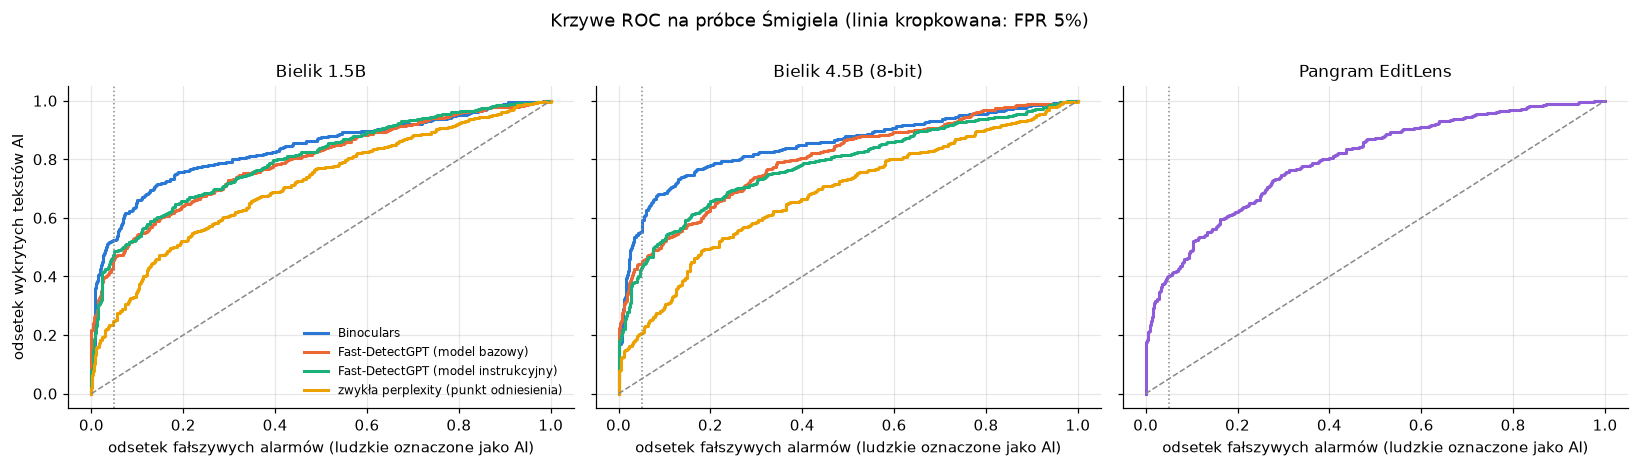

In [7]:
def roc_curve(machine: pd.Series, labels: pd.Series) -> tuple[np.ndarray, np.ndarray]:
    order = np.argsort(-machine.to_numpy(), kind="stable")
    y = labels.to_numpy().astype(int)[order]
    return (
        np.r_[0, np.cumsum(1 - y) / (1 - y).sum()],
        np.r_[0, np.cumsum(y) / y.sum()],
    )


fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 4.2), sharey=True)
for ax, p in zip(axes, PANELS, strict=True):
    for det, name in PANEL_DETECTORS[p].items():
        fpr_, tpr_ = roc_curve(machine_score(smigiel[p], det), smigiel[p]["label"])
        ax.plot(fpr_, tpr_, color=DET_COLOR[det], lw=2, label=name)
    ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
    ax.axvline(MAIN_FPR, color=GRAY, ls=":", lw=1)
    ax.set_title(PANELS[p])
    ax.set_xlabel("odsetek fałszywych alarmów (ludzkie oznaczone jako AI)")
axes[0].set_ylabel("odsetek wykrytych tekstów AI")
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Krzywe ROC na próbce Śmigiela (linia kropkowana: FPR 5%)", y=1.0)
fig.tight_layout()
plt.show()

Jak to czytać: im bardziej krzywa wypycha się w lewy górny róg, tym lepiej.
Interesuje nas lewa część wykresu (niskie FPR), bo tam pracujemy: przy FPR 5% i 1% **większość tekstów AI i tak nie zostanie wykryta** (patrz `recall_at_fpr`).
To wprost ogranicza, jak małe zjawisko jesteśmy w stanie zobaczyć w naszych danych (sekcja 8).

## 3. Gdzie leżą nasze artykuły na tle znanych tekstów

Rozkład wyniku Binoculars (niższy = bardziej AI).
Linie ciągłe to **nasze artykuły**, kropkowane to **Śmigiel**.
Jeśli artykuły z lat 2023–2025 zawierają dużo AI, ich rozkład powinien wyraźnie przesunąć się w stronę rozkładu AI ze Śmigiela (pomarańczowa kropkowana).

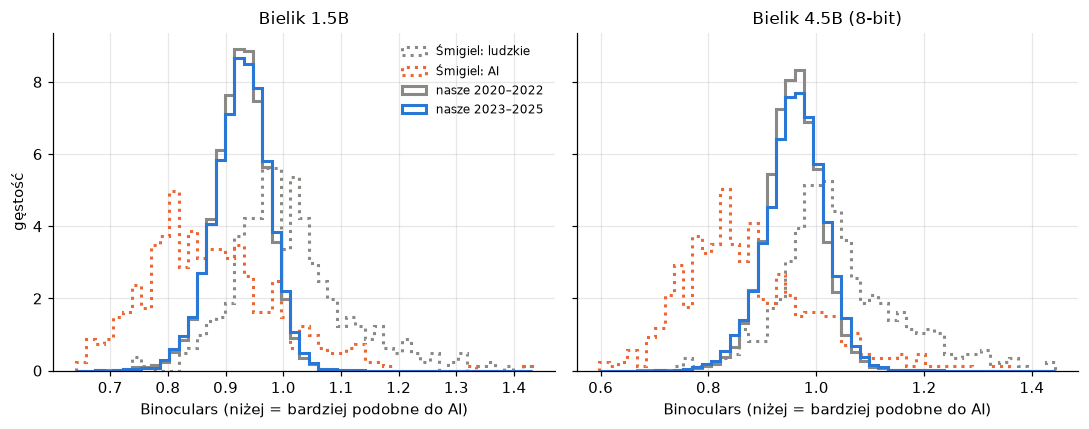

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, p in zip(axes, PRESETS, strict=True):
    series = {
        "Śmigiel: ludzkie": (
            smigiel[p].loc[smigiel[p]["label"] == 0, "binoculars"],
            GRAY,
            ":",
        ),
        "Śmigiel: AI": (
            smigiel[p].loc[smigiel[p]["label"] == 1, "binoculars"],
            ORANGE,
            ":",
        ),
        "nasze 2020–2022": (data[p].loc[data[p]["human"], "binoculars"], GRAY, "-"),
        "nasze 2023–2025": (data[p].loc[~data[p]["human"], "binoculars"], BLUE, "-"),
    }
    lo = min(s.quantile(0.005) for s, _, _ in series.values())
    hi = max(s.quantile(0.995) for s, _, _ in series.values())
    bins = np.linspace(lo, hi, 50)
    for name, (values, color, style) in series.items():
        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            lw=2,
            color=color,
            ls=style,
            label=name,
        )
    ax.set_title(PRESETS[p])
    ax.set_xlabel("Binoculars (niżej = bardziej podobne do AI)")
axes[0].set_ylabel("gęstość")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4. Kalibracja i test placebo

**Fałszywe alarmy na zbiorze `test` (lata 2020–2022, nieużywane do ustawienia progu).**
Jeśli wynik jest blisko docelowego FPR, próg się stabilnie przenosi na nowe teksty.

In [9]:
held = pd.concat(
    [
        pd.read_csv(DETECT_DIR / "reports" / p / "calibration.csv").assign(
            model=PRESETS[p]
        )
        for p in PRESETS
    ]
)
# Pangram nie zależy od presetu: raport każdego presetu ma te same wiersze
held.loc[held["detector"] == PANGRAM, "model"] = PANGRAM_NAME
held = held.drop_duplicates(["model", "detector", "target_fpr"])
held["detector"] = held["detector"].map(DET_NAMES)
held["fpr_heldout (95% CI)"] = held.apply(
    lambda r: (
        f"{pct(r.fpr_heldout)} [{pct(r.fpr_heldout_ci_low)}; {pct(r.fpr_heldout_ci_high)}]"
    ),
    axis=1,
)
display(
    held.pivot_table(
        index=["model", "detector"],
        columns="target_fpr",
        values="fpr_heldout (95% CI)",
        aggfunc="first",
    )
)

target_fpr                                                              0.01               0.05
model               detector                                                                   
Bielik 1.5B         Binoculars                             0.9% [0.6%; 1.4%]  5.0% [4.1%; 6.0%]
                    Fast-DetectGPT (model bazowy)          1.2% [0.8%; 1.8%]  4.9% [4.0%; 5.9%]
                    Fast-DetectGPT (model instrukcyjny)    1.1% [0.8%; 1.7%]  5.0% [4.1%; 6.0%]
                    zwykła perplexity (punkt odniesienia)  1.1% [0.8%; 1.7%]  5.2% [4.3%; 6.2%]
Bielik 4.5B (8-bit) Binoculars                             1.1% [0.7%; 1.6%]  4.4% [3.6%; 5.4%]
                    Fast-DetectGPT (model bazowy)          0.8% [0.5%; 1.3%]  4.7% [3.8%; 5.7%]
                    Fast-DetectGPT (model instrukcyjny)    1.0% [0.6%; 1.5%]  5.7% [4.8%; 6.8%]
                    zwykła perplexity (punkt odniesienia)  1.0% [0.6%; 1.5%]  4.7% [3.9%; 5.7%]
Pangram EditLens    Pangram EditLens                       0.5% [0.3%; 0.9%]  4.4% [3.6%; 5.4%]

**Test placebo: odsetek oznaczonych w każdym roku (próg przy FPR 5%).**
W latach 2020–2022 powinien leżeć na linii przerywanej (5%) z definicji. Jeśli te lata się rozjeżdżają, to detektor reaguje na coś innego niż AI.
Wynik właściwy to lata 2023–2025 (zacieniowane): AI w treściach podniosłoby punkty **ponad** linię.
Słupki to 95% przedziały ufności (Wilson).

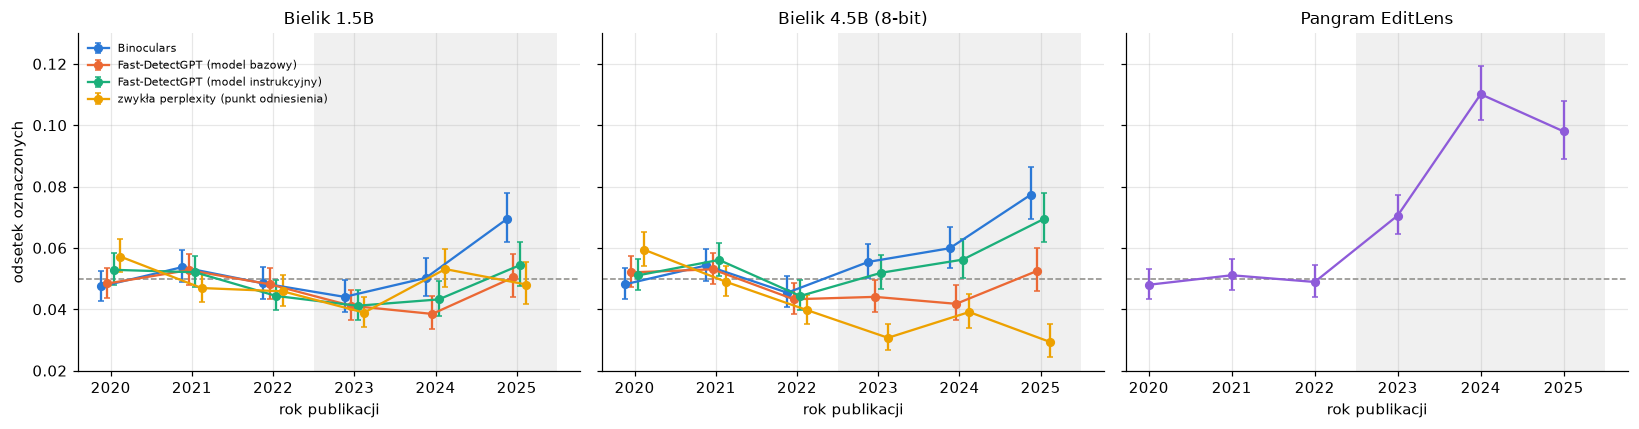

In [41]:
def rate_by_year(p: str, det: str, fpr: float) -> pd.DataFrame:
    df, f = data[p], flags[(p, det, fpr)]
    rows = []
    for year, idx in df.groupby("pub_year").groups.items():
        k, n = int(f[idx].sum()), len(idx)
        lo, hi = wilson_interval(k, n)
        rows.append(
            {"pub_year": year, "n": n, "flagged": k, "rate": k / n, "lo": lo, "hi": hi}
        )
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 4), sharey=True)
for ax, p in zip(axes, PANELS, strict=True):
    ax.axvspan(2022.5, 2025.5, color=GRAY, alpha=0.12, lw=0)
    ax.axhline(MAIN_FPR, color=GRAY, ls="--", lw=1)
    dets = PANEL_DETECTORS[p]
    for i, (det, name) in enumerate(dets.items()):
        t = rate_by_year(p, det, MAIN_FPR)
        x = t["pub_year"] + (i - (len(dets) - 1) / 2) * 0.08
        ax.errorbar(
            x,
            t["rate"],
            yerr=[t["rate"] - t["lo"], t["hi"] - t["rate"]],
            color=DET_COLOR[det],
            marker="o",
            ms=5,
            lw=1.5,
            capsize=2,
            label=name,
        )
    ax.set_title(PANELS[p])
    ax.set_xlabel("rok publikacji")
    ax.set_ylim(0.02, 0.13)
axes[0].set_ylabel("odsetek oznaczonych")
axes[0].legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

## 5. Wynik główny: 2023–2025 kontra 2020–2022

Dla każdego detektora: odsetek oznaczonych w latach 2020–2022 (poziom bazowy, powinien być ≈ FPR) i w latach 2023–2025, ich różnica oraz jednostronny test Fishera (czy odsetek w 2023–2025 jest **większy**).

In [11]:
@cache
def fisher(k1: int, n1: int, k0: int, n0: int) -> float:
    return fisher_greater(k1, n1, k0, n0)


def compare_periods(
    p: str, det: str, fpr: float, subset: pd.Series | None = None
) -> dict:
    df, f = data[p], flags[(p, det, fpr)]
    keep = pd.Series(True, index=df.index) if subset is None else subset
    before, after = f[keep & df["human"]], f[keep & ~df["human"]]
    n0, k0, n1, k1 = len(before), int(before.sum()), len(after), int(after.sum())
    return {
        "n 2020–22": n0,
        "oznaczone 2020–22": k0,
        "odsetek 2020–22": k0 / n0,
        "n 2023–25": n1,
        "oznaczone 2023–25": k1,
        "odsetek 2023–25": k1 / n1,
        "różnica (pp)": 100 * (k1 / n1 - k0 / n0),
        "p (Fisher)": fisher(k1, n1, k0, n0),
    }


rows = []
for fpr in FPRS:
    for p in PANELS:
        for det, name in PANEL_DETECTORS[p].items():
            rows.append(
                {
                    "FPR": f"{fpr:.0%}",
                    "model": PANELS[p],
                    "detektor": name,
                    **compare_periods(p, det, fpr),
                }
            )
overall = pd.DataFrame(rows)
fmt = {
    "odsetek 2020–22": pct,
    "odsetek 2023–25": pct,
    "różnica (pp)": "{:+.1f}".format,
    "p (Fisher)": "{:.3f}".format,
}
display(overall.set_index(["FPR", "model", "detektor"]).style.format(fmt))

**Podział na strata** (S1 = najpopularniejsze serwisy z rankingu, S2 = pozostałe z rankingu, S3 = dodane ręcznie), Binoculars przy FPR 5%.

In [12]:
rows = []
for p in PRESETS:
    for stratum in sorted(articles["stratum"].unique()):
        subset = data[p]["stratum"] == stratum
        rows.append(
            {
                "model": PRESETS[p],
                "stratum": stratum,
                **compare_periods(p, "binoculars", MAIN_FPR, subset),
            }
        )
by_stratum = pd.DataFrame(rows).set_index(["model", "stratum"])
display(by_stratum.style.format(fmt))

## 6. Domeny

Dla każdej z 44 domen: odsetek oznaczonych w 2020–2022 i 2023–2025, test Fishera i poprawka na wielokrotne testowanie (q-value, Benjamini–Hochberg).
**Przy 44 testach na poziomie 5% około 2 domen wyjdzie „istotnych” z samego przypadku**, dlatego patrzymy na q-value i na to, czy te same domeny wychodzą w obu modelach.

In [13]:
def domain_table(p: str, det: str, fpr: float) -> pd.DataFrame:
    df, f = data[p], flags[(p, det, fpr)]
    rows = []
    for domain, group in df.groupby("domain"):
        before, after = f[group.index[group["human"]]], f[group.index[~group["human"]]]
        n0, k0, n1, k1 = len(before), int(before.sum()), len(after), int(after.sum())
        rows.append(
            {
                "domain": domain,
                "stratum": group["stratum"].iloc[0],
                "n_2020_22": n0,
                "rate_2020_22": k0 / n0 if n0 else np.nan,
                "n_2023_25": n1,
                "flagged_2023_25": k1,
                "rate_2023_25": k1 / n1 if n1 else np.nan,
                "p_value": fisher(k1, n1, k0, n0) if n0 and n1 else np.nan,
            }
        )
    table = pd.DataFrame(rows).set_index("domain")
    table["excess"] = table["rate_2023_25"] - table["rate_2020_22"]
    tested = table["p_value"].notna()
    table.loc[tested, "q_value"] = benjamini_hochberg(table.loc[tested, "p_value"])
    return table


domains = {
    (p, det): domain_table(p, det, MAIN_FPR)
    for p in PANELS
    for det in PANEL_DETECTORS[p]
}

summary = pd.DataFrame(
    {
        f"{PANELS[p]} / {name}": {
            "domen z p<0,05": int((domains[(p, det)]["p_value"] < 0.05).sum()),
            "domen z q<0,10": int((domains[(p, det)]["q_value"] < 0.10).sum()),
            "oczekiwane z p<0,05 przy braku efektu": round(
                0.05 * domains[(p, det)]["p_value"].notna().sum(), 1
            ),
        }
        for p in PANELS
        for det, name in PANEL_DETECTORS[p].items()
    }
).T
display(summary)

,"domen z p<0,05","domen z q<0,10","oczekiwane z p<0,05 przy braku efektu"
Bielik 1.5B / Binoculars,11.0,10.0,2.1
Bielik 1.5B / Fast-DetectGPT (model bazowy),4.0,0.0,2.1
Bielik 1.5B / Fast-DetectGPT (model instrukcyjny),3.0,2.0,2.1
Bielik 1.5B / zwykła perplexity (punkt odniesienia),12.0,9.0,2.1
Bielik 4.5B (8-bit) / Binoculars,14.0,14.0,2.1
Bielik 4.5B (8-bit) / Fast-DetectGPT (model bazowy),5.0,3.0,2.1
Bielik 4.5B (8-bit) / Fast-DetectGPT (model instrukcyjny),9.0,8.0,2.1
Bielik 4.5B (8-bit) / zwykła perplexity (punkt odniesienia),6.0,4.0,2.1
Pangram EditLens / Pangram EditLens,22.0,22.0,2.1


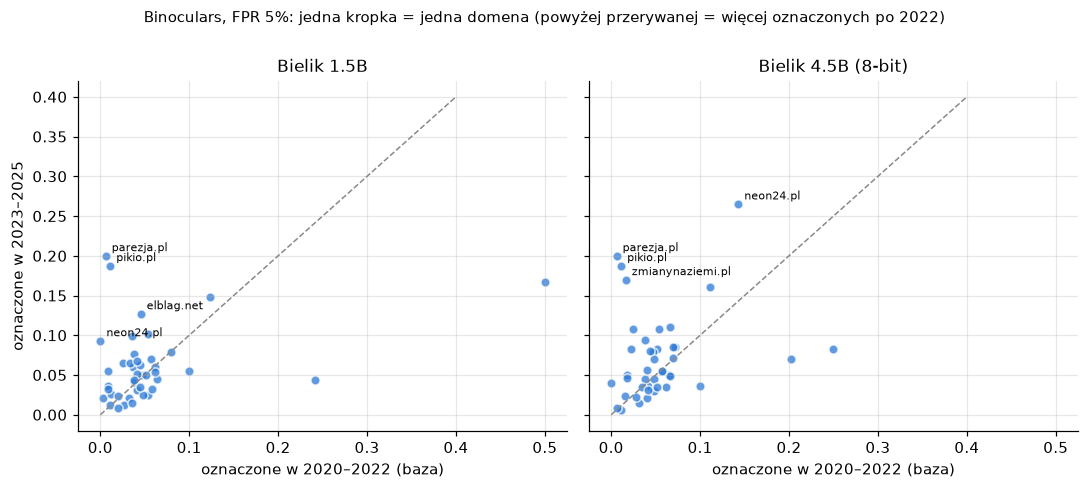

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
for ax, p in zip(axes, PRESETS, strict=True):
    t = domains[(p, "binoculars")].dropna(subset=["rate_2020_22", "rate_2023_25"])
    ax.plot([0, 0.4], [0, 0.4], color=GRAY, ls="--", lw=1)
    ax.scatter(
        t["rate_2020_22"],
        t["rate_2023_25"],
        s=36,
        color=BLUE,
        alpha=0.75,
        edgecolor="white",
        linewidth=1,
    )
    for domain, row in t.nlargest(4, "excess").iterrows():
        ax.annotate(
            domain,
            (row["rate_2020_22"], row["rate_2023_25"]),
            fontsize=7,
            xytext=(4, 3),
            textcoords="offset points",
        )
    ax.set_title(PRESETS[p])
    ax.set_xlabel("oznaczone w 2020–2022 (baza)")
axes[0].set_ylabel("oznaczone w 2023–2025")
fig.suptitle(
    "Binoculars, FPR 5%: jedna kropka = jedna domena (powyżej przerywanej = więcej oznaczonych po 2022)",
    y=1.0,
    fontsize=10,
)
fig.tight_layout()
plt.show()

In [15]:
top = pd.concat(
    [
        domains[(p, "binoculars")]
        .nsmallest(8, "p_value")
        .assign(model=PRESETS[p])
        .reset_index()
        for p in PRESETS
    ]
)
display(
    top[
        [
            "model",
            "domain",
            "stratum",
            "n_2020_22",
            "rate_2020_22",
            "n_2023_25",
            "rate_2023_25",
            "p_value",
            "q_value",
        ]
    ]
    .set_index(["model", "domain"])
    .style.format(
        {
            "rate_2020_22": pct,
            "rate_2023_25": pct,
            "p_value": "{:.3f}".format,
            "q_value": "{:.2f}".format,
        }
    )
)

Jak to czytać: domena jest przekonującym kandydatem, jeśli (a) ma wysoki `rate_2023_25` przy niskim `rate_2020_22`, (b) ma małe q-value i (c) pojawia się **w obu modelach i w kilku detektorach**.
Na jedną domenę przypada tu zaledwie 25–75 tekstów na okres, więc pojedyncze wyniki są bardzo niepewne.

## 7. Zgodność detektorów i modeli

Jeśli detektory naprawdę wykrywają to samo zjawisko, powinny wskazywać te same teksty i te same domeny.
Niska zgodność znaczy, że w dużej części to szum.

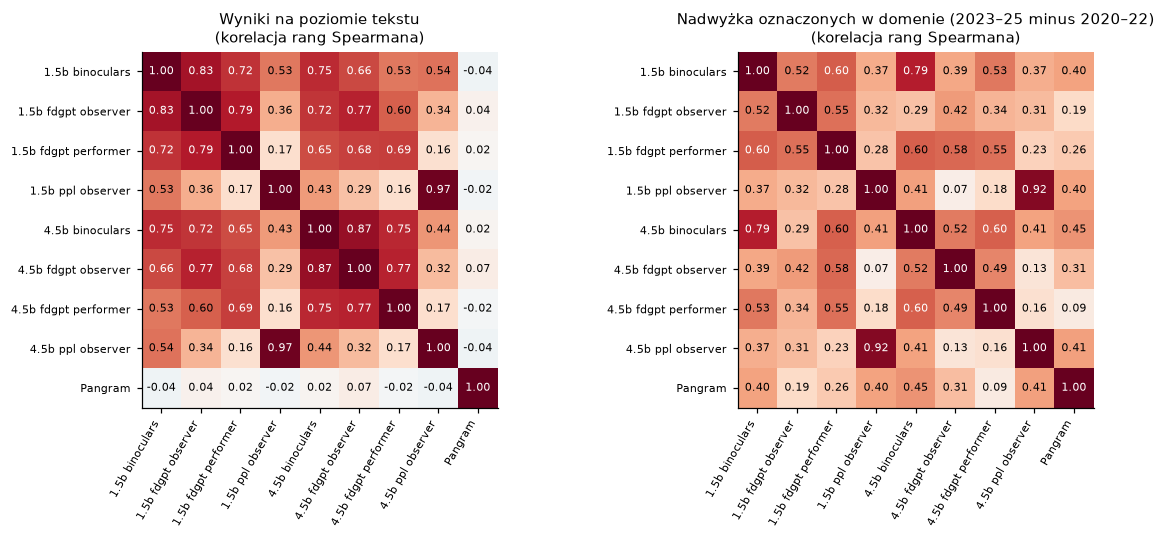

In [16]:
def short(p: str, det: str) -> str:
    if det == PANGRAM:
        return "Pangram"
    return f"{p.removeprefix('bielik-')} {det.replace('fastdetectgpt_', 'fdgpt ').replace('logppl_', 'ppl ')}"


def heatmap(ax, matrix: pd.DataFrame, title: str) -> None:
    im = ax.imshow(matrix.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(
        range(len(matrix)), matrix.columns, rotation=60, ha="right", fontsize=7
    )
    ax.set_yticks(range(len(matrix)), matrix.index, fontsize=7)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value = matrix.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if abs(value) > 0.6 else "black",
            )
    ax.grid(False)
    ax.set_title(title, fontsize=10)
    return im


# Indeks to article_id, bo Pangram może mieć wynik dla innego zbioru artykułów
text_scores = pd.DataFrame(
    {
        short(p, det): pd.Series(
            machine_score(data[p], det).to_numpy(),
            index=data[p]["article_id"].to_numpy(),
        )
        for p in PANELS
        for det in PANEL_DETECTORS[p]
    }
)
domain_excess = pd.DataFrame(
    {
        short(p, det): domains[(p, det)]["excess"]
        for p in PANELS
        for det in PANEL_DETECTORS[p]
    }
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
heatmap(
    axes[0],
    text_scores.corr(method="spearman"),
    "Wyniki na poziomie tekstu\n(korelacja rang Spearmana)",
)
heatmap(
    axes[1],
    domain_excess.corr(method="spearman"),
    "Nadwyżka oznaczonych w domenie (2023–25 minus 2020–22)\n(korelacja rang Spearmana)",
)
fig.tight_layout()
plt.show()

- **Na poziomie tekstu** Binoculars i oba warianty Fast-DetectGPT są silnie skorelowane (0,6–0,9), czyli mierzą podobne zjawisko, i to niezależnie od rozmiaru modelu.
- **Zwykła perplexity** (`ppl observer`) zachowuje się inaczej: koreluje z resztą słabo (0,2–0,5), a między modelem 1.5B i 4.5B niemal idealnie (0,98).
  To znaczy, że głównie mierzy „trudność” samego tekstu (temat, słownictwo), a nie to, czy napisała go maszyna. Dlatego traktujemy ją tylko jako punkt odniesienia.
- **Na poziomie domen** zgodność jest wyraźnie niższa (dla Binoculars między modelami około 0,65, dla pozostałych par często poniżej 0,4).
  To sygnał ostrzegawczy: przy kilkudziesięciu tekstach na okres różnice między domenami to w dużej części szum losowania.
- **Pangram** nie koreluje na poziomie tekstu z żadnym detektorem Bielika (współczynnik od −0,03 do 0,07), czyli mierzy coś innego niż przewidywalność tekstu dla modelu językowego. Na poziomie domen zgodność jest umiarkowana: nadwyżka Pangrama koreluje z nadwyżką Binoculars na 1.5B na poziomie 0,29, a na 4.5B na poziomie 0,48. Szczegóły w sekcjach 11–15.

In [17]:
# Czy te same teksty z lat 2023-2025 są oznaczane przez oba modele? (Binoculars, FPR 5%)
a = flags[(SMALL, "binoculars", MAIN_FPR)]
b = flags[(LARGE, "binoculars", MAIN_FPR)]
after = ~data[SMALL]["human"]
rows = []
for label, mask in (("2020–2022", ~after), ("2023–2025", after)):
    n = int(mask.sum())
    both, only_s, only_l = (
        int((a & b & mask).sum()),
        int((a & ~b & mask).sum()),
        int((~a & b & mask).sum()),
    )
    expected = a[mask].mean() * b[mask].mean() * n
    rows.append(
        {
            "okres": label,
            "n": n,
            "oba modele": both,
            "tylko 1.5B": only_s,
            "tylko 4.5B": only_l,
            "oba modele przy niezależności": round(expected, 1),
        }
    )
display(pd.DataFrame(rows).set_index("okres"))

,n,oba modele,tylko 1.5B,tylko 4.5B,oba modele przy niezależności
okres,,,,,
2020–2022,20956,539,507,496,51.7
2023–2025,14867,459,322,470,48.8


## 8. Moc testu i korekta na czułość

To najważniejsza sekcja do interpretacji wyniku.

**Problem.** Detektor wykrywa tylko część tekstów AI (czułość, TPR; na Śmigielu przy FPR 5% to około połowa).
Jeśli w domenie 20% tekstów to AI, a detektor widzi połowę z nich, to odsetek oznaczonych wzrośnie tylko o ok. 10 punktów procentowych, a przy 75 tekstach na okres to trudno odróżnić od losowości.

**8a. Szacunek udziału AI.** Jeśli odsetek oznaczonych w danej grupie to `r`, bazowy odsetek fałszywych alarmów to `b` (z lat 2020–2022), a czułość to `TPR`, to udział AI w grupie wynosi w przybliżeniu

`udział AI ≈ (r − b) / (TPR − b)`.

Czułości nie znamy dla naszych artykułów (Śmigiel ma inny charakter niż polskie newsy i inne generatory niż te, których używają serwisy), więc **pokazujemy wynik dla całego przedziału możliwych TPR**.
Wartość ujemna lub bliska zeru oznacza: brak nadwyżki ponad poziom bazowy.

In [18]:
tprs = [0.2, 0.35, 0.5, 0.7, 0.9]
rows = []
for p in PRESETS:
    c = compare_periods(p, "binoculars", MAIN_FPR)
    b, r, n1 = c["odsetek 2020–22"], c["odsetek 2023–25"], c["n 2023–25"]
    lo, hi = wilson_interval(c["oznaczone 2023–25"], n1)
    tpr_smigiel_p = tpr_smigiel[(p, "binoculars", MAIN_FPR)]
    for t in tprs + [tpr_smigiel_p]:
        rows.append(
            {
                "model": PRESETS[p],
                "założona czułość (TPR)": f"{t:.2f}"
                + (" (ze Śmigiela)" if t == tpr_smigiel_p else ""),
                "szacowany udział AI w 2023–25": (r - b) / (t - b),
                "95% CI (tylko niepewność r)": f"[{pct((lo - b) / (t - b))}; {pct((hi - b) / (t - b))}]",
            }
        )
prevalence = pd.DataFrame(rows)
display(
    prevalence.set_index(["model", "założona czułość (TPR)"]).style.format(
        {"szacowany udział AI w 2023–25": pct}
    )
)

**8b. Jak duże zjawisko jesteśmy w stanie zobaczyć w pojedynczej domenie?**
Symulacja: domena ma 75 tekstów z lat 2020–2022 i 75 z lat 2023–2025 (typowa liczebność w naszych danych).
Zakładamy, że w 2023–2025 pewien udział tekstów to AI wykrywane z czułością TPR ze Śmigiela, a pozostałe są oznaczane na poziomie FPR.
Pokazujemy, jak często test Fishera (p<0,05) wykryłby taką domenę (moc testu).

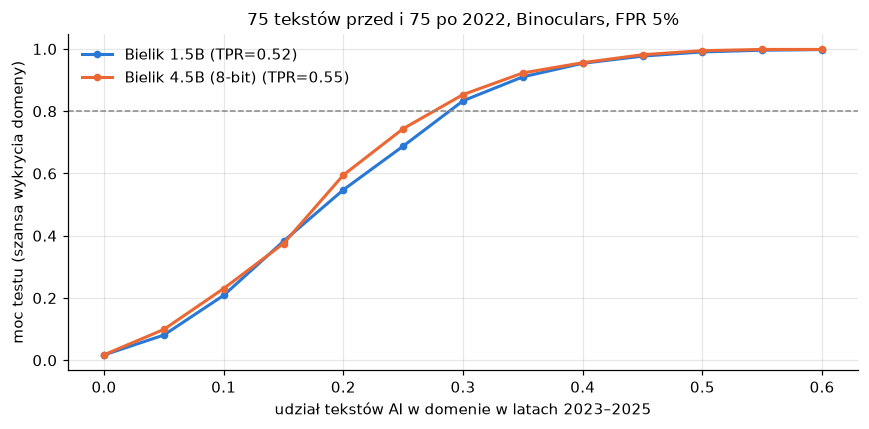

Najmniejszy udział AI wykrywany z mocą >= 80%: {'Bielik 1.5B': '30.0%', 'Bielik 4.5B (8-bit)': '30.0%'}


In [19]:
rng = np.random.default_rng(42)
shares = np.arange(0, 0.65, 0.05)
REPS = 2000


def power(n0: int, n1: int, base: float, tpr: float, share: float) -> float:
    k0 = rng.binomial(n0, base, REPS)
    k1 = rng.binomial(n1, base * (1 - share) + tpr * share, REPS)
    return float(
        np.mean(
            [
                fisher(int(x1), n1, int(x0), n0) < 0.05
                for x1, x0 in zip(k1, k0, strict=True)
            ]
        )
    )


fig, ax = plt.subplots(figsize=(8, 4))
needed = {}
for p, color in zip(PRESETS, [BLUE, ORANGE], strict=True):
    tpr = tpr_smigiel[(p, "binoculars", MAIN_FPR)]
    curve = [power(75, 75, MAIN_FPR, tpr, s) for s in shares]
    ax.plot(
        shares,
        curve,
        color=color,
        marker="o",
        ms=4,
        lw=2,
        label=f"{PRESETS[p]} (TPR={tpr:.2f})",
    )
    reached = [s for s, c in zip(shares, curve, strict=True) if c >= 0.8]
    needed[PRESETS[p]] = reached[0] if reached else None
ax.axhline(0.8, color=GRAY, ls="--", lw=1)
ax.set_xlabel("udział tekstów AI w domenie w latach 2023–2025")
ax.set_ylabel("moc testu (szansa wykrycia domeny)")
ax.set_title("75 tekstów przed i 75 po 2022, Binoculars, FPR 5%")
ax.legend()
fig.tight_layout()
plt.show()
print(
    "Najmniejszy udział AI wykrywany z mocą >= 80%:",
    {k: (pct(v) if v is not None else "poza zakresem") for k, v in needed.items()},
)

Interpretacja: domena, w której AI to mniej niż wskazany udział, **pozostanie niewidoczna** nawet jeśli detektor działa dobrze.
Brak istotnej domeny nie dowodzi więc, że nikt nie używa AI — dowodzi tylko, że nie ma domen, w których AI stanowi dużą część tekstów (w zakresie czułości detektora na takim materiale).

## 9. Kandydaci do ręcznego przeglądu

Teksty z lat 2023–2025, które **oba modele** oznaczyły metodą Binoculars przy FPR 5%.
To nie jest lista „artykułów z AI”: przy FPR 5% część z nich to fałszywe alarmy.
Lista służy do (a) ręcznego przejrzenia kilkunastu tekstów, (b) wysłania do drugiego niezależnego detektora (np. Pangram API), (c) porównania z losowymi tekstami z lat 2020–2022.

Plik `data/detect/candidates.csv` zawiera tylko adresy URL, metadane i wyniki (bez treści artykułów).

In [20]:
mask = (
    (~data[SMALL]["human"])
    & flags[(SMALL, "binoculars", MAIN_FPR)]
    & flags[(LARGE, "binoculars", MAIN_FPR)]
)
candidates = pd.DataFrame(
    {
        "domain": data[SMALL]["domain"],
        "stratum": data[SMALL]["stratum"],
        "pub_year": data[SMALL]["pub_year"],
        "url": data[SMALL]["url"],
        "title": data[SMALL]["title"],
        "binoculars_1.5b": data[SMALL]["binoculars"],
        "binoculars_4.5b": data[LARGE]["binoculars"],
        "fdgpt_obs_1.5b": data[SMALL]["fastdetectgpt_observer"],
        "fdgpt_obs_4.5b": data[LARGE]["fastdetectgpt_observer"],
    }
)[mask]
candidates["mean_binoculars"] = candidates[["binoculars_1.5b", "binoculars_4.5b"]].mean(
    axis=1
)
candidates = candidates.sort_values("mean_binoculars").reset_index(drop=True)
candidates.to_csv(DETECT_DIR / "candidates.csv", index=False)

a, b = flags[(SMALL, "binoculars", MAIN_FPR)], flags[(LARGE, "binoculars", MAIN_FPR)]
later = ~data[SMALL]["human"]
base_both = (a & b & ~later).sum() / (~later).sum()
print(f"{len(candidates)} kandydatów z {int(later.sum())} tekstów z lat 2023–2025")
print(
    f"Dla porównania: w latach 2020–2022 oba modele oznaczają {pct(base_both)} tekstów, "
    f"więc przy tym samym poziomie spodziewamy się ok. {base_both * later.sum():.0f} fałszywych alarmów "
    f"wśród tych {len(candidates)} kandydatów."
)
display(
    candidates.head(15)[
        ["domain", "pub_year", "title", "mean_binoculars", "url"]
    ].style.format({"mean_binoculars": "{:.3f}".format})
)
display(
    candidates.groupby("domain")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("liczba kandydatów")
    .to_frame()
)

459 kandydatów z 14867 tekstów z lat 2023–2025
Dla porównania: w latach 2020–2022 oba modele oznaczają 2.6% tekstów, więc przy tym samym poziomie spodziewamy się ok. 382 fałszywych alarmów wśród tych 459 kandydatów.


,domain,pub_year,title,mean_binoculars,url
0,tvn24.pl,2024,"Czołowe zderzenie, nie żyje jeden z kierowców",0.700,https://tvn24.pl/kujawsko-pomorskie/dolna-grupa-czolowe-zderzenie-samochodow-nie-zyje-kierowca-st8207286
1,lelum.pl,2024,Poznasz gwiazdę po brodzie? 5 pytanie to łatwizna,0.720,https://lifestyle.lelum.pl/quizy/gwiazdy/poznasz-gwiazde-po-brodzie-5-pytanie-to-latwizna-mp-mk-270824
2,epoznan.pl,2023,IMGW wydał ostrzeżenie pierwszego stopnia. Również dla Poznania,0.728,https://epoznan.pl/news-news-142986-imgw_wydal_ostrzezenie_pierwszego_stopnia_rowniez_dla_poznania
3,o2.pl,2024,Znasz tych ludzi? Natychmiast dzwoń na policję,0.742,https://www.o2.pl/informacje/znasz-tych-ludzi-natychmiast-dzwon-na-policje-7030187146250944a
4,epoznan.pl,2025,Zaginął poznaniak!,0.743,https://epoznan.pl/news-news-159995-zaginal_poznaniak
5,epoznan.pl,2023,Zamykają jedną z ulic. Już dziś będzie tu Wigilia!,0.744,https://epoznan.pl/news-news-146073-zamykaja_jedna_z_ulic_juz_dzis_bedzie_tu_wigilia
6,rmf24.pl,2024,Fałszywe faktury na 48 mln zł. Służby rozbiły grupę przestępczą,0.746,"https://www.rmf24.pl/regiony/olsztyn/news-falszywe-faktury-na-48-mln-zl-sluzby-rozbily-grupe-przestepc,nId,7868039"
7,niezalezna.pl,2024,Masło Ghee. Wszechstronny i zdrowy skarb w kuchni | Niezalezna.pl,0.747,https://niezalezna.pl/lifestyle/zdrowie-i-dom/maslo-ghee-wszechstronny-i-zdrowy-skarb-w-kuchni/523961
8,niezalezna.pl,2025,"Sensacja w Ekstraklasie. Faworyt naciskał, ale znów nie dał rady [WIDEO] | Niezalezna.pl",0.748,https://niezalezna.pl/sport/pilka-nozna/sensacja-w-ekstraklasie-faworyt-naciskal-ale-znow-nie-dal-rady-wideo/558425
9,rmf24.pl,2025,Wyjątkowa okazja dla miłośników astronomii. Geminidy rozświetlą niebo,0.748,"https://www.rmf24.pl/nauka/news-wyjatkowa-okazja-dla-milosnikow-astronomii-geminidy-rozswiet,nId,8050491"


,liczba kandydatów
domain,
tvmalbork.pl,41
tvn24.pl,35
epoznan.pl,32
rmf24.pl,31
dziennik.pl,26
o2.pl,21
fakt.pl,20
elblag.net,17
onet.pl,17


## 10. Bez progu: czy wyniki z 2023–2025 różnią się od wyników z 2020–2022?

Dotychczasowe porównania zależą od wybranego FPR (1% albo 5%). Tu dwa sposoby, które nie wymagają wyboru jednego progu:

- **AUC „po kontra przed”**: prawdopodobieństwo, że losowy tekst z lat 2023–2025 ma wynik bardziej „AI” niż losowy tekst z lat 2020–2022. Wartość 0,5 znaczy: rozkłady są takie same, im dalej od 0,5, tym większe przesunięcie. Przedział to 95% przedział percentylowy z bootstrapu (300 losowań tekstów ze zwracaniem).
- **Nadwyżka oznaczonych w funkcji FPR**: różnica odsetka oznaczonych po i przed 2023 dla progów od 0,5% do 15% FPR, z 95% przedziałem Newcombe’a. Jeśli wniosek jest odporny, wykres nie zmienia znaku ani nie znika po zmianie progu.

In [21]:
def auc_shift(after: np.ndarray, before: np.ndarray) -> float:
    """Szansa, że losowy tekst z 2023–25 ma wynik bardziej „AI” niż losowy z 2020–22 (remis = 1/2)."""
    ranks = pd.Series(np.concatenate([after, before])).rank().to_numpy()
    n1, n0 = len(after), len(before)
    return float((ranks[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


rng_boot = np.random.default_rng(7)
BOOT = 300
rows = []
for p in PANELS:
    df = data[p]
    is_human = df["human"].to_numpy()
    for det, name in PANEL_DETECTORS[p].items():
        score = machine_score(df, det).to_numpy()
        after_scores, before_scores = score[~is_human], score[is_human]
        boot = [
            auc_shift(
                rng_boot.choice(after_scores, len(after_scores)),
                rng_boot.choice(before_scores, len(before_scores)),
            )
            for _ in range(BOOT)
        ]
        low, high = np.percentile(boot, [2.5, 97.5])
        rows.append(
            {
                "model": PANELS[p],
                "detektor": name,
                "AUC": auc_shift(after_scores, before_scores),
                "95% CI": f"[{low:.3f}; {high:.3f}]",
                "różnica istotna": "tak" if low > 0.5 or high < 0.5 else "nie",
            }
        )
display(
    pd.DataFrame(rows)
    .set_index(["model", "detektor"])
    .style.format({"AUC": "{:.3f}".format})
)

Jak to czytać:

- **Binoculars (0,50 w obu modelach) i Fast-DetectGPT na modelu bazowym nie pokazują żadnego przesunięcia.** Fast-DetectGPT na modelu instrukcyjnym ma AUC poniżej 0,5 (0,48), czyli teksty z lat 2023–2025 są tam nieco *mniej* podobne do AI. Zwykła perplexity na 1.5B pokazuje przesunięcie w drugą stronę (0,53), ale drugi model go nie potwierdza (0,51, przedział obejmuje 0,5).
- **Pangram ma AUC 0,58 (95% CI 0,56–0,59): rozkład jego wyniku w latach 2023–2025 jest wyraźnie przesunięty w stronę „AI”.**

Uwaga: AUC jest mało czułe na małą domieszkę AI. Orientacyjnie, jeśli AI jest rozdzielane od tekstów ludzkich tak jak na Śmigielu (AUC ≈ 0,8), to udział AI równy 5% daje AUC ≈ 0,515, a 15% ≈ 0,545.
Wynik 0,50 wyklucza więc przesunięcie całego rozkładu, ale **nie wyklucza kilku procent tekstów AI** (to samo ograniczenie co w sekcji 8).

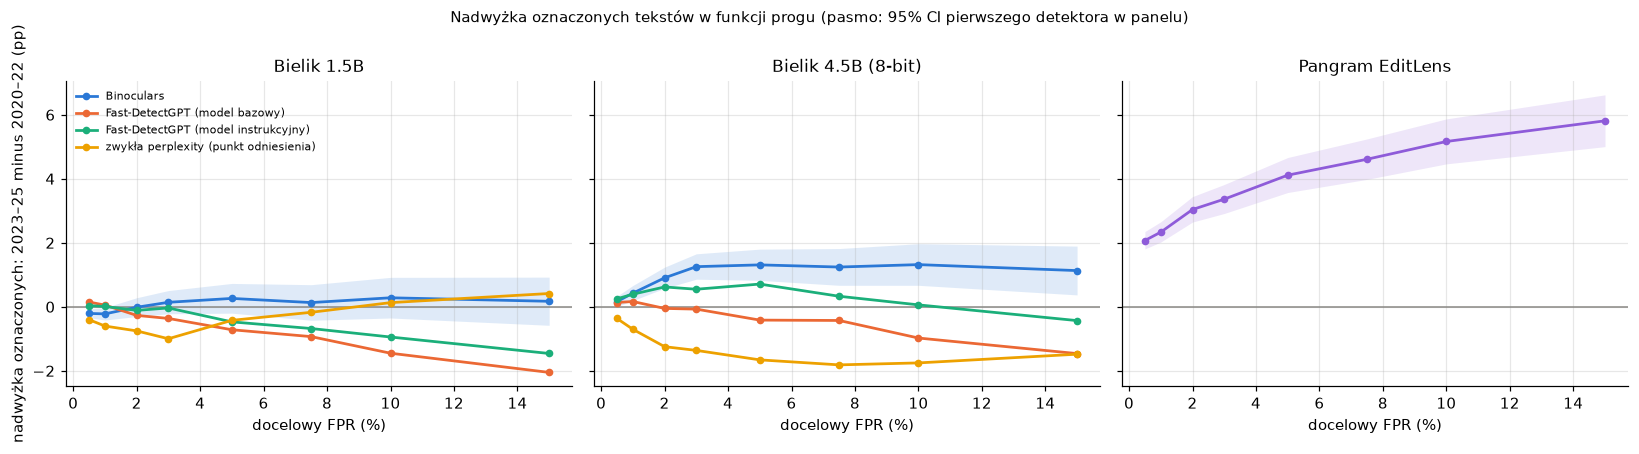

In [22]:
FPR_GRID = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.15]


def newcombe(k1: int, n1: int, k0: int, n0: int) -> tuple[float, float]:
    """95% przedział dla różnicy dwóch odsetków (metoda Newcombe’a)."""
    r1, r0 = k1 / n1, k0 / n0
    low1, high1 = wilson_interval(k1, n1)
    low0, high0 = wilson_interval(k0, n0)
    return (
        (r1 - r0) - float(np.hypot(r1 - low1, high0 - r0)),
        (r1 - r0) + float(np.hypot(high1 - r1, r0 - low0)),
    )


def excess_curve(p: str, det: str) -> pd.DataFrame:
    df, score = data[p], machine_score(data[p], det)
    n0, n1 = int(df["human"].sum()), int((~df["human"]).sum())
    rows = []
    for fpr in FPR_GRID:
        flag = score > calibrate(df, det, fpr)
        k0, k1 = int(flag[df["human"]].sum()), int(flag[~df["human"]].sum())
        low, high = newcombe(k1, n1, k0, n0)
        rows.append(
            {
                "fpr": 100 * fpr,
                "excess": 100 * (k1 / n1 - k0 / n0),
                "low": 100 * low,
                "high": 100 * high,
            }
        )
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 4), sharey=True)
for ax, p in zip(axes, PANELS, strict=True):
    ax.axhline(0, color=GRAY, lw=1)
    for i, (det, name) in enumerate(PANEL_DETECTORS[p].items()):
        curve = excess_curve(p, det)
        ax.plot(
            curve["fpr"],
            curve["excess"],
            color=DET_COLOR[det],
            marker="o",
            ms=4,
            lw=1.8,
            label=name,
        )
        if i == 0:
            ax.fill_between(
                curve["fpr"],
                curve["low"],
                curve["high"],
                color=DET_COLOR[det],
                alpha=0.15,
                lw=0,
            )
    ax.set_title(PANELS[p])
    ax.set_xlabel("docelowy FPR (%)")
axes[0].set_ylabel("nadwyżka oznaczonych: 2023–25 minus 2020–22 (pp)")
axes[0].legend(fontsize=7, loc="upper left")
fig.suptitle(
    "Nadwyżka oznaczonych tekstów w funkcji progu (pasmo: 95% CI pierwszego detektora w panelu)",
    y=1.0,
    fontsize=10,
)
fig.tight_layout()
plt.show()

- **Bielik:** krzywe leżą w pobliżu zera (do około +1,5 pp) przy każdym progu od 0,5% do 10% FPR, a pasmo Binoculars obejmuje zero w całym zakresie. Brak nadwyżki nie wynika więc z wyboru 1% albo 5%. Jedyne odstępstwo to zwykła perplexity (1.5B) przy FPR 15% (+2,9 pp), czyli przy progu, przy którym fałszywych alarmów jest już bardzo dużo.
- **Pangram:** nadwyżka jest dodatnia przy każdym progu i pasmo nigdzie nie dotyka zera: od +2,7 pp (FPR 0,5%) do +7,5 pp (FPR 15%).

Oba wyniki są więc odporne na wybór progu: różnica między Bielikiem a Pangramem nie bierze się stąd, że wybraliśmy akurat 1% albo 5%. Trzeba jeszcze pamiętać o sekcji 12: po poprawce na długość tekstu Bielik też pokazuje niewielką dodatnią nadwyżkę.

## 11. Pangram EditLens: co zwraca i jak zmienia się w czasie

Pangram EditLens to klasyfikator, nie miara zaskoczenia: Llama-3.2-3B z adapterem LoRA i głową o czterech klasach, od **0 (tekst ludzki)** do **3 (AI)**.
`pangram_score` to oczekiwana klasa przeskalowana do [0, 1], a `pangram_bucket` to klasa najbardziej prawdopodobna.
Model był uczony **tylko na angielskim**, a my podajemy mu polskie teksty (do 1024 tokenów, zapisane małymi literami), więc jego zachowanie na polszczyźnie trzeba traktować jako hipotezę, którą sprawdzają sekcje 2 (Śmigiel) i 12–14.

Poniżej: rozkład klas po latach oraz odsetek oznaczonych (próg FPR 5% z lat 2020–2022) w kolejnych kwartałach, obok Binoculars. Pionowa linia to premiera ChatGPT (30.11.2022).

In [23]:
assert HAS_PANGRAM, (
    "Sekcje 11–15 wymagają data/detect/pangram.csv i smigiel-pangram.csv"
)
pg = data["pangram"]
bucket_by_year = pd.crosstab(pg["pub_year"], pg["pangram_bucket"], normalize="index")
bucket_by_year.columns = [f"klasa {c}" for c in bucket_by_year.columns]
by_year_score = pg.groupby("pub_year")["pangram_score"]
bucket_by_year["średni wynik"] = by_year_score.mean()
bucket_by_year["mediana wyniku"] = by_year_score.median()
display(
    bucket_by_year.style.format(
        {c: pct for c in bucket_by_year.columns if c.startswith("klasa")}
        | {"średni wynik": "{:.3f}".format, "mediana wyniku": "{:.3f}".format}
    )
)

,klasa 0,klasa 1,klasa 2,klasa 3,średni wynik,mediana wyniku
pub_year,,,,,,
2020,93.3%,2.7%,0.8%,3.3%,0.139,0.070
2021,92.9%,2.9%,0.9%,3.3%,0.144,0.075
2022,93.1%,2.9%,0.8%,3.2%,0.143,0.077
2023,90.4%,3.8%,0.5%,5.3%,0.162,0.087
2024,85.8%,5.1%,1.3%,7.8%,0.193,0.112
2025,83.8%,8.9%,1.1%,6.2%,0.191,0.122


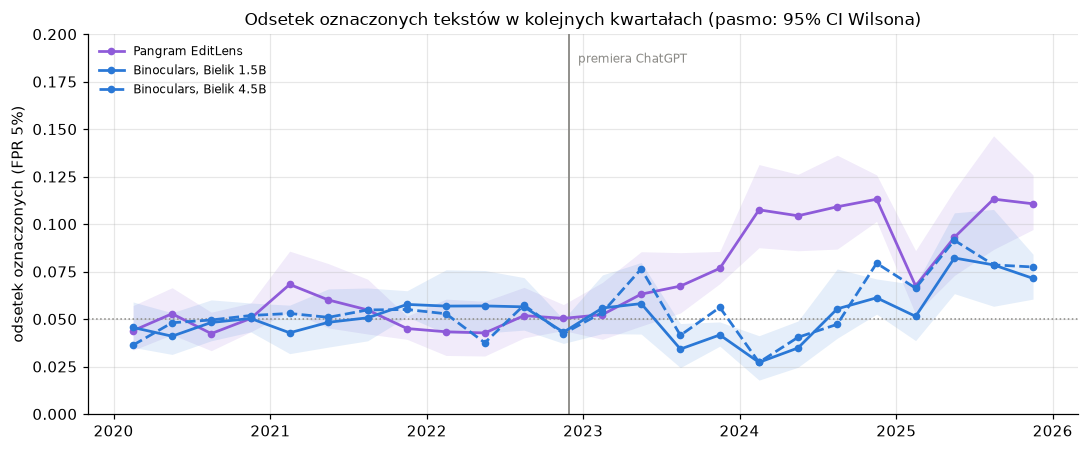

In [24]:
def quarterly(p: str, det: str, fpr: float = MAIN_FPR) -> pd.DataFrame:
    df, flag = data[p], flags[(p, det, fpr)]
    quarter = df["pub_date"].dt.to_period("Q")
    rows = []
    for q, idx in df.groupby(quarter).groups.items():
        k, n = int(flag[idx].sum()), len(idx)
        low, high = wilson_interval(k, n)
        rows.append(
            {
                "mid": q.start_time + (q.end_time - q.start_time) / 2,
                "rate": k / n,
                "low": low,
                "high": high,
                "n": n,
            }
        )
    return pd.DataFrame(rows)


series = [
    ("Pangram EditLens", "pangram", PANGRAM, DET_COLOR[PANGRAM], "-"),
    ("Binoculars, Bielik 1.5B", SMALL, "binoculars", DET_COLOR["binoculars"], "-"),
    ("Binoculars, Bielik 4.5B", LARGE, "binoculars", DET_COLOR["binoculars"], "--"),
]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axhline(MAIN_FPR, color=GRAY, ls=":", lw=1)
ax.axvline(pd.Timestamp("2022-11-30"), color=GRAY, lw=1.2)
ax.text(pd.Timestamp("2022-12-20"), 0.185, "premiera ChatGPT", fontsize=8, color=GRAY)
for i, (label, p, det, color, style) in enumerate(series):
    q = quarterly(p, det)
    ax.plot(
        q["mid"],
        q["rate"],
        color=color,
        ls=style,
        marker="o",
        ms=4,
        lw=1.8,
        label=label,
    )
    if i < 2:
        ax.fill_between(q["mid"], q["low"], q["high"], color=color, alpha=0.12, lw=0)
ax.set_ylim(0, 0.2)
ax.set_ylabel("odsetek oznaczonych (FPR 5%)")
ax.set_title(
    "Odsetek oznaczonych tekstów w kolejnych kwartałach (pasmo: 95% CI Wilsona)"
)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

- **Klasy:** w latach 2020–2022 klasa 0 („człowiek”) to 92–94% tekstów, a klasa 3 („AI”) 2,9–3,4%. W 2023 r. klasa 3 rośnie do 5,9%, w 2024 do 9,9%, w 2025 do 7,5%, a klasa 0 spada do 82%.
- **Średni wynik** jest płaski w latach 2020–2022 (0,14–0,16) i rośnie po 2022 r. (0,18 w 2023, 0,21 w 2024 i 2025).
- **Oś czasu:** Pangram trzyma się poziomu bazowego (około 5%) do końca 2022 r. i dopiero w 2023 r. zaczyna rosnąć (5–9% w kwartałach), a w latach 2024–2025 osiąga 9–16% (wyjątek: 2025 Q1, około 5%). Binoculars na obu modelach zostaje przy 2–11% bez trendu. Pojedynczy kwartał ma od 83 do 619 tekstów, więc pasma są szerokie, ale kierunek jest czytelny.
- Ten wzrost zaczyna się mniej więcej w czasie premiery ChatGPT, co zgadza się z hipotezą o AI, ale **jej nie dowodzi**: po 2022 r. mógł się zmienić także skład domen w próbce, format stron albo styl pisania.

## 12. Czy wzrost u Pangrama to tylko efekt długości tekstu?

Pangram jest klasyfikatorem, więc może reagować na cechy inne niż autorstwo, np. na długość.
Sprawdzamy trzy rzeczy: (a) jak wynik zależy od liczby słów, (b) czy wzrost po 2022 r. zostaje, gdy **próg ustawiamy osobno w ośmiu przedziałach długości** (równoliczne kwantyle słów, każdy kalibrowany na tekstach z lat 2020–2022 z `train` i `dev`), (c) czy w każdym przedziale długości rozkład z 2023–2025 jest przesunięty względem 2020–2022 (AUC w przedziale).

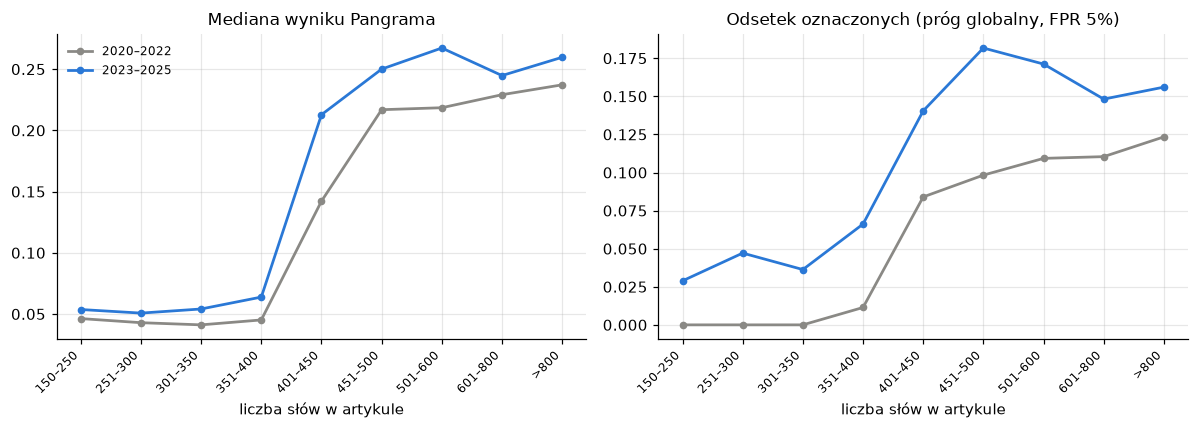

length_bin        150–250  251–300  301–350  351–400  401–450  451–500  501–600  601–800  >800
liczba artykułów     8399     4126     3653     3069     2568     2107     2818     3119  5105


In [25]:
LENGTH_EDGES = [149, 250, 300, 350, 400, 450, 500, 600, 800, 10**5]
LENGTH_LABELS = [
    "150–250",
    "251–300",
    "301–350",
    "351–400",
    "401–450",
    "451–500",
    "501–600",
    "601–800",
    ">800",
]
pg = pg.assign(length_bin=pd.cut(pg["n_words"], LENGTH_EDGES, labels=LENGTH_LABELS))
pg_flag = flags[("pangram", PANGRAM, MAIN_FPR)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(LENGTH_LABELS))
for is_human, label, color in ((True, "2020–2022", GRAY), (False, "2023–2025", BLUE)):
    mask = pg["human"] == is_human
    median = pg[mask].groupby("length_bin", observed=True)["pangram_score"].median()
    rate = pg_flag[mask].groupby(pg.loc[mask, "length_bin"], observed=True).mean()
    axes[0].plot(
        x,
        median.reindex(LENGTH_LABELS).to_numpy(),
        color=color,
        marker="o",
        ms=4,
        lw=1.8,
        label=label,
    )
    axes[1].plot(
        x,
        rate.reindex(LENGTH_LABELS).to_numpy(),
        color=color,
        marker="o",
        ms=4,
        lw=1.8,
        label=label,
    )
for ax, title in zip(
    axes,
    ("Mediana wyniku Pangrama", "Odsetek oznaczonych (próg globalny, FPR 5%)"),
    strict=True,
):
    ax.set_xticks(x, LENGTH_LABELS, rotation=45, ha="right", fontsize=8)
    ax.set_xlabel("liczba słów w artykule")
    ax.set_title(title)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
print(
    pg.groupby("length_bin", observed=True)
    .size()
    .rename("liczba artykułów")
    .to_frame()
    .T.to_string()
)

- **Wynik Pangrama silnie zależy od długości i ma wyraźny próg.** Poniżej około 400 słów mediana wyniku wynosi około 0,05 w obu okresach, a powyżej 400 słów skacze do 0,15–0,29. Jeśli polski tekst daje około 2,5 tokenu Llamy na słowo, 400 słów to w przybliżeniu limit 1024 tokenów, więc **możliwe, że Pangram zachowuje się inaczej dla tekstów mieszczących się w oknie i dla ucinanych**. To hipoteza do sprawdzenia, nie ustalony fakt.
- **Skutek dla progu:** przy jednym progu dla wszystkich tekstów **żaden** artykuł z lat 2020–2022 o długości do 350 słów (45% wszystkich artykułów) nie jest oznaczony, a fałszywe alarmy pochodzą z długich tekstów.
- **W każdym przedziale długości** 2023–2025 leży powyżej 2020–2022, zarówno w medianie wyniku, jak i w odsetku oznaczonych. Sam rozkład długości tego nie wyjaśnia: artykuły z lat 2023–2025 są tylko nieco dłuższe (średnio 549 wobec 522 słów).

In [26]:
def length_stratified_flags(p: str, det: str, fpr: float, n_bins: int = 8) -> pd.Series:
    """Próg ustawiany osobno w każdym przedziale długości (równoliczne kwantyle słów)."""
    df = data[p]
    score = machine_score(df, det)
    strata = pd.qcut(df["n_words"], n_bins, labels=False, duplicates="drop")
    flag = pd.Series(False, index=df.index)
    for stratum in strata.unique():
        idx = df.index[(strata == stratum).to_numpy()]
        calibration = df.loc[idx, "human"] & df.loc[idx, "split"].isin(["train", "dev"])
        flag[idx] = score[idx] > threshold_at_fpr(score[idx][calibration], fpr)
    return flag


def compare_flag(flag: pd.Series, df: pd.DataFrame) -> dict:
    n0, k0 = int(df["human"].sum()), int(flag[df["human"]].sum())
    n1, k1 = int((~df["human"]).sum()), int(flag[~df["human"]].sum())
    return {
        "odsetek 2020–22": k0 / n0,
        "odsetek 2023–25": k1 / n1,
        "różnica (pp)": 100 * (k1 / n1 - k0 / n0),
        "p (Fisher)": fisher(k1, n1, k0, n0),
    }


rows = []
for fpr in FPRS:
    for p, det in (("pangram", PANGRAM), (SMALL, "binoculars"), (LARGE, "binoculars")):
        for threshold_kind, flag in (
            ("jeden próg dla wszystkich", flags[(p, det, fpr)]),
            ("próg w przedziałach długości", length_stratified_flags(p, det, fpr)),
        ):
            rows.append(
                {
                    "FPR": f"{fpr:.0%}",
                    "model": PANELS[p],
                    "detektor": DET_NAMES[det],
                    "próg": threshold_kind,
                    **compare_flag(flag, data[p]),
                }
            )
display(
    pd.DataFrame(rows).set_index(["FPR", "model", "detektor", "próg"]).style.format(fmt)
)

Po ustawieniu progu osobno w ośmiu przedziałach długości:

- **Pangram: nadwyżka zostaje i rośnie** (FPR 5%: +5,0 → +10,6 pp; FPR 1%: +3,0 → +5,4 pp; p<0,001). Większa wartość przy progach w przedziałach wynika głównie z krótkich tekstów, gdzie próg jest bardzo niski. Traktujemy to jako dowód, że długość wzrostu **nie tłumaczy**, a nie jako lepszy szacunek jego wielkości.
- **Bielik: z poprawką na długość pojawia się mała dodatnia nadwyżka.** Przy FPR 5% Binoculars 1.5B ma +1,2 pp (p=0,03), a Binoculars 4.5B +2,0 pp (p=0,001). Przy FPR 1% tylko 4.5B (+1,5 pp, p<0,001), a 1.5B nie (+0,2 pp, p=0,24).
  Możliwe wyjaśnienie: odsetek fałszywych alarmów Binoculars maleje z długością tekstu, a artykuły z lat 2023–2025 są nieco dłuższe, więc jeden próg dla wszystkich lekko zaniża nadwyżkę.

To zmienia ocenę z sekcji 5: **bez poprawki na długość Bielik nie pokazuje nadwyżki, z poprawką pokazuje niewielką (1–2 pp), zgodną kierunkiem z Pangramem.**
Poprawkę na długość wprowadziliśmy po zobaczeniu wyników (uzasadnioną zależnością fałszywych alarmów od długości), więc brzegowe p-wartości (0,03) trzeba traktować ostrożnie.

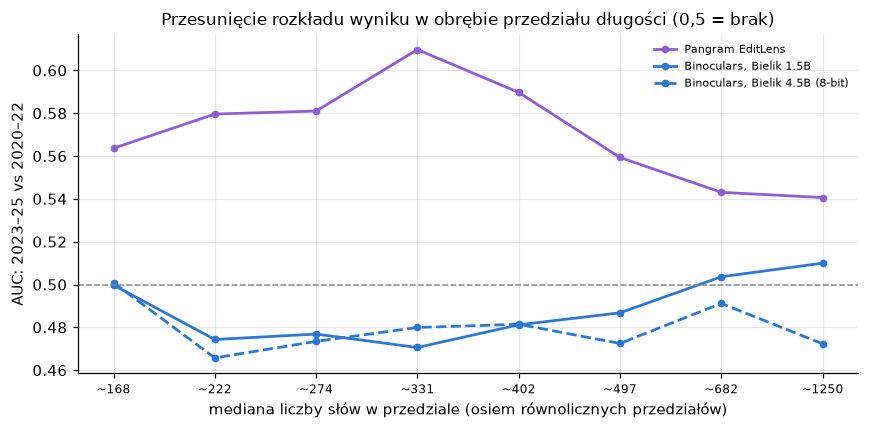

In [27]:
N_STRATA = 8
fig, ax = plt.subplots(figsize=(8, 4))
for p, det, style in (
    ("pangram", PANGRAM, "-"),
    (SMALL, "binoculars", "-"),
    (LARGE, "binoculars", "--"),
):
    df = data[p]
    strata = pd.qcut(df["n_words"], N_STRATA, labels=False)
    score = machine_score(df, det)
    aucs, medians = [], []
    for s in range(N_STRATA):
        in_stratum = (strata == s).to_numpy()
        is_human = df["human"].to_numpy()
        aucs.append(
            auc_shift(
                score.to_numpy()[in_stratum & ~is_human],
                score.to_numpy()[in_stratum & is_human],
            )
        )
        medians.append(int(df.loc[in_stratum, "n_words"].median()))
    ax.plot(
        range(N_STRATA),
        aucs,
        color=DET_COLOR[det],
        ls=style,
        marker="o",
        ms=4,
        lw=1.8,
        label=DET_NAMES[det] if p == "pangram" else f"{DET_NAMES[det]}, {PANELS[p]}",
    )
ax.axhline(0.5, color=GRAY, ls="--", lw=1)
ax.set_xticks(range(N_STRATA), [f"~{m}" for m in medians], fontsize=8)
ax.set_xlabel("mediana liczby słów w przedziale (osiem równolicznych przedziałów)")
ax.set_ylabel("AUC: 2023–25 vs 2020–22")
ax.set_title("Przesunięcie rozkładu wyniku w obrębie przedziału długości (0,5 = brak)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

- **Pangram:** AUC powyżej 0,5 w każdym z ośmiu przedziałów (0,53–0,62), najwyższe dla tekstów poniżej 400 słów (0,60–0,62).
- **Binoculars:** w obrębie przedziałów krąży wokół 0,5 (0,44–0,52) z jednym wyjątkiem: w przedziale około 700 słów AUC wynosi 0,59 (1.5B) i 0,57 (4.5B). Przy ośmiu przedziałach po około 600 tekstów taki skok może być przypadkiem, więc na nim nie opieramy wniosków.

Przesunięcie Pangrama jest zatem widoczne w całym zakresie długości, a nie tylko w jednym przedziale.

## 13. Pangram: czy wzrost jest szeroki, czy skupiony w kilku domenach?

Test Fishera i poprawka Benjaminiego–Hochberga jak w sekcji 6, ale dla Pangrama.
Dodatkowo „nadwyżka w liczbie tekstów” = oznaczone w 2023–2025 minus liczba, jakiej oczekiwalibyśmy przy poziomie bazowym tej domeny z lat 2020–2022. Pokazuje, **ile oznaczonych tekstów** przybyło, a nie tylko o ile punktów procentowych.

Domen z oboma okresami: 42; z p<0,05: 22 (z samego przypadku oczekiwane: 2.1); z q<0,10: 22
Łączna nadwyżka oznaczonych tekstów po 2022 r.: 654; 5 domen o największej nadwyżce odpowiada za 327 (50.1%)


,domen z dodatnią nadwyżką,z ujemną,bez zmiany,"p (test znaków, jednostronny)"
Pangram,34,7,1,0.000
Binoculars 1.5B,25,17,0,0.140
Binoculars 4.5B,24,18,0,0.220


,stratum,n_2020_22,rate_2020_22,n_2023_25,rate_2023_25,nadwyżka (liczba tekstów),p_value,q_value
domain,,,,,,,,
zmianynaziemi.pl,S2,551,3.1%,312,36.2%,103.4,0.0000,0.000
lelum.pl,S3,540,2.0%,411,9.2%,29.6,0.0000,0.000
goniec.pl,S2,283,5.3%,600,15.7%,62.2,0.0000,0.000
nczas.com,S3,600,3.5%,241,12.4%,21.6,0.0000,0.000
o2.pl,S1,600,0.8%,600,4.8%,24.0,0.0000,0.000
pikio.pl,S3,270,4.8%,16,43.8%,6.2,0.0000,0.000
tvmalbork.pl,S2,541,3.5%,405,10.1%,26.8,0.0000,0.000
dziennik.pl,S1,581,3.4%,600,8.7%,31.3,0.0001,0.001
elblag.net,S3,442,6.6%,260,15.0%,21.9,0.0003,0.001


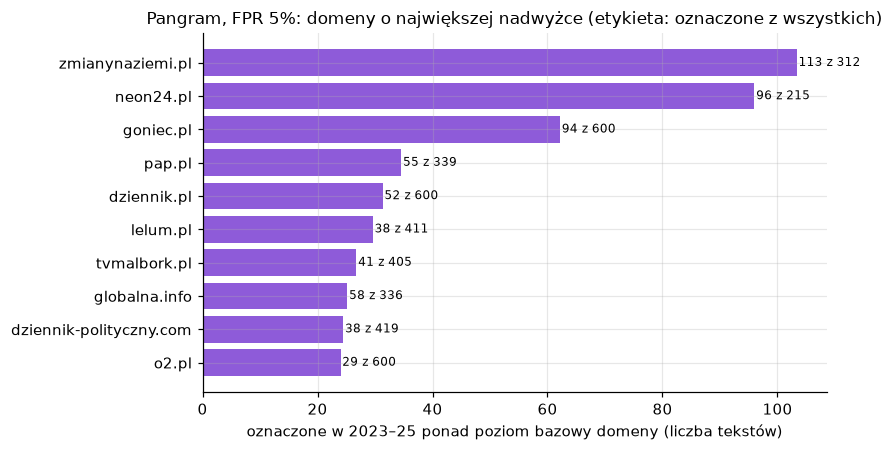

In [28]:
from math import comb

pangram_domains = domains[("pangram", PANGRAM)].copy()
pangram_domains["nadwyżka (liczba tekstów)"] = (
    pangram_domains["flagged_2023_25"]
    - pangram_domains["rate_2020_22"] * pangram_domains["n_2023_25"]
)
tested = pangram_domains["p_value"].notna()
print(
    f"Domen z oboma okresami: {int(tested.sum())}; "
    f"z p<0,05: {int((pangram_domains['p_value'] < 0.05).sum())} (z samego przypadku oczekiwane: {0.05 * tested.sum():.1f}); "
    f"z q<0,10: {int((pangram_domains['q_value'] < 0.10).sum())}"
)
excess_total = pangram_domains["nadwyżka (liczba tekstów)"].sum()
excess_top = pangram_domains["nadwyżka (liczba tekstów)"].nlargest(5).sum()
print(
    f"Łączna nadwyżka oznaczonych tekstów po 2022 r.: {excess_total:.0f}; "
    f"5 domen o największej nadwyżce odpowiada za {excess_top:.0f} ({pct(excess_top / excess_total)})"
)
sign_rows = {}
for label, key in (
    ("Pangram", ("pangram", PANGRAM)),
    ("Binoculars 1.5B", (SMALL, "binoculars")),
    ("Binoculars 4.5B", (LARGE, "binoculars")),
):
    change = domains[key]["excess"].dropna()
    up, down = int((change > 0).sum()), int((change < 0).sum())
    sign_rows[label] = {
        "domen z dodatnią nadwyżką": up,
        "z ujemną": down,
        "bez zmiany": len(change) - up - down,
        "p (test znaków, jednostronny)": sum(
            comb(up + down, k) for k in range(up, up + down + 1)
        )
        / 2 ** (up + down),
    }
display(
    pd.DataFrame.from_dict(sign_rows, orient="index").style.format(
        {"p (test znaków, jednostronny)": "{:.3f}".format}
    )
)
display(
    pangram_domains.nsmallest(10, "p_value")[
        [
            "stratum",
            "n_2020_22",
            "rate_2020_22",
            "n_2023_25",
            "rate_2023_25",
            "nadwyżka (liczba tekstów)",
            "p_value",
            "q_value",
        ]
    ].style.format(
        {
            "rate_2020_22": pct,
            "rate_2023_25": pct,
            "nadwyżka (liczba tekstów)": "{:.1f}".format,
            "p_value": "{:.4f}".format,
            "q_value": "{:.3f}".format,
        }
    )
)

top = pangram_domains.nlargest(10, "nadwyżka (liczba tekstów)").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top["nadwyżka (liczba tekstów)"], color=DET_COLOR[PANGRAM])
for y, (_, row) in enumerate(top.iterrows()):
    ax.text(
        row["nadwyżka (liczba tekstów)"] + 0.3,
        y,
        f"{int(row['flagged_2023_25'])} z {int(row['n_2023_25'])}",
        va="center",
        fontsize=8,
    )
ax.set_xlabel("oznaczone w 2023–25 ponad poziom bazowy domeny (liczba tekstów)")
ax.set_title(
    "Pangram, FPR 5%: domeny o największej nadwyżce (etykieta: oznaczone z wszystkich)"
)
fig.tight_layout()
plt.show()

- **Pięć domen ma q<0,10:** `zmianynaziemi.pl` (25 z 50 tekstów oznaczonych, przy 0% w latach 2020–2022), `nczas.com` (24%), `pikio.pl` (6 z 13), `tvmalbork.pl` (16%) i `lelum.pl` (11,5%). To 5 domen z 40, a z p<0,05 jest ich 6 przy oczekiwanych 2 z samego przypadku. **Żadna nie należy do S1** (największe serwisy z rankingu); `gazeta.pl` (S1) ma p=0,018, ale tylko 7 tekstów z lat 2023–2025.
- **Wzrost nie jest jednak tylko kilkoma domenami.** Pięć domen o największej nadwyżce odpowiada za 53% całej nadwyżki (`zmianynaziemi.pl` sama za około 20%), a **28 z 40 domen ma dodatnią nadwyżkę** (test znaków p=0,003). Dla Binoculars podobny test nie wychodzi istotny (22 z 35, p=0,09 dla 1.5B; 19 z 32, p=0,19 dla 4.5B).

In [29]:
strong = pangram_domains.index[pangram_domains["q_value"] < 0.10]
rows = []
for label, p, det in (
    ("Pangram", "pangram", PANGRAM),
    ("Binoculars 1.5B", SMALL, "binoculars"),
    ("Binoculars 4.5B", LARGE, "binoculars"),
):
    for scope, subset in (
        ("wszystkie domeny", None),
        (
            f"bez {len(strong)} domen z q<0,10 u Pangrama",
            ~data[p]["domain"].isin(strong),
        ),
    ):
        rows.append(
            {
                "detektor": label,
                "zakres": scope,
                **compare_periods(p, det, MAIN_FPR, subset),
            }
        )
display(
    pd.DataFrame(rows)
    .set_index(["detektor", "zakres"])[
        [
            "n 2023–25",
            "odsetek 2020–22",
            "odsetek 2023–25",
            "różnica (pp)",
            "p (Fisher)",
        ]
    ]
    .style.format(fmt)
)
print("Domeny odjęte:", ", ".join(strong))

cross = pd.DataFrame(
    {
        "Pangram: nadwyżka (pp)": 100 * pangram_domains.loc[strong, "excess"],
        "Pangram: q": pangram_domains.loc[strong, "q_value"],
        "Binoculars 1.5B: nadwyżka (pp)": 100
        * domains[(SMALL, "binoculars")].loc[strong, "excess"],
        "Binoculars 1.5B: p": domains[(SMALL, "binoculars")].loc[strong, "p_value"],
        "Binoculars 4.5B: nadwyżka (pp)": 100
        * domains[(LARGE, "binoculars")].loc[strong, "excess"],
        "Binoculars 4.5B: p": domains[(LARGE, "binoculars")].loc[strong, "p_value"],
    }
)
display(
    cross.style.format(
        {c: "{:+.1f}".format for c in cross.columns if "pp" in c}
        | {c: "{:.3f}".format for c in cross.columns if c.endswith(("q", "p"))}
    )
)

Domeny odjęte: demagog.org.pl, dziennik-polityczny.com, dziennik.pl, dziennikwschodni.pl, elblag.net, gazeta.pl, globalna.info, goniec.pl, interia.pl, lelum.pl, money.pl, nczas.com, neon24.pl, nowiny24.pl, o2.pl, pap.pl, parezja.pl, pikio.pl, polsatnews.pl, tvmalbork.pl, tvrepublika.pl, zmianynaziemi.pl


,Pangram: nadwyżka (pp),Pangram: q,Binoculars 1.5B: nadwyżka (pp),Binoculars 1.5B: p,Binoculars 4.5B: nadwyżka (pp),Binoculars 4.5B: p
domain,,,,,,
demagog.org.pl,+6.0,0.015,+4.6,0.000,+3.3,0.004
dziennik-polityczny.com,+5.8,0.003,-1.0,0.826,-0.5,0.716
dziennik.pl,+5.2,0.001,+1.3,0.209,+3.2,0.020
dziennikwschodni.pl,+4.9,0.040,+6.3,0.002,+5.6,0.005
elblag.net,+8.4,0.001,+8.2,0.000,+8.3,0.000
gazeta.pl,+16.6,0.015,+0.4,0.611,+6.1,0.115
globalna.info,+7.5,0.009,+1.8,0.023,-0.5,0.861
goniec.pl,+10.4,0.000,-1.0,0.870,+2.9,0.022
interia.pl,+3.9,0.028,-19.7,1.000,-13.2,1.000


- **Bez tych pięciu domen** nadwyżka Pangrama spada o połowę (+5,0 → +2,6 pp), ale zostaje istotna (p<0,001). Domeny wybraliśmy po zobaczeniu danych, a odjęcie największych nadwyżek działa na niekorzyść wyniku, więc to ocena zachowawcza. U Bielika po odjęciu tych domen nadwyżka znika (+0,0 pp i −0,1 pp). Czyli **mała nadwyżka Bielika pochodzi z tych samych pięciu domen, a Pangram widzi dodatkowo szerszy wzrost**.
- **Tabela krzyżowa:** nadwyżka Binoculars jest dodatnia lub zerowa we wszystkich pięciu domenach (od +0,0 do +21 pp). Nominalnie istotne (p<0,05) są `pikio.pl` w obu modelach, `tvmalbork.pl` w 1.5B i `zmianynaziemi.pl` w 4.5B. Dwa niezależne detektory wskazują więc te same serwisy, choć w różnym stopniu.

## 14. Zgodność Pangrama z Bielikiem i detektor „zgodny”

Pangram i Binoculars mierzą zupełnie różne rzeczy (klasyfikator wyuczony na przykładach kontra przewidywalność tekstu dla modelu językowego), więc **tekst oznaczony przez oba jest znacznie mocniejszym kandydatem** niż oznaczony przez jeden.
Sprawdzamy: (a) czy oba detektory wskazują wspólne teksty częściej, niż wynikałoby z przypadku, osobno w obu okresach, (b) co daje łączenie ich na Śmigielu (znane etykiety), (c) jaki udział AI wynika z reguły „oba oznaczają”, (d) zapisujemy listę takich tekstów do ręcznego przeglądu.

In [30]:
# Te same artykuły w tej samej kolejności we wszystkich panelach (article_id nie jest unikalny)
assert (pg["article_id"].to_numpy() == data[SMALL]["article_id"].to_numpy()).all()


def article_flags(fpr: float) -> pd.DataFrame:
    """Flagi Pangrama i Binoculars (1.5B) dla każdego artykułu."""
    return pd.DataFrame(
        {
            "human": pg["human"],
            "pangram": flags[("pangram", PANGRAM, fpr)],
            "binoculars": flags[(SMALL, "binoculars", fpr)],
        }
    )


by_article = article_flags(MAIN_FPR)
rows = []
for label, mask in (
    ("2020–2022", by_article["human"]),
    ("2023–2025", ~by_article["human"]),
):
    sub = by_article[mask]
    n, k_pangram, k_bino = (
        len(sub),
        int(sub["pangram"].sum()),
        int(sub["binoculars"].sum()),
    )
    both = int((sub["pangram"] & sub["binoculars"]).sum())
    rows.append(
        {
            "okres": label,
            "n": n,
            "oznaczone przez Pangram": k_pangram,
            "oznaczone przez Binoculars 1.5B": k_bino,
            "oznaczone przez oba": both,
            "oba przy niezależności": round(k_pangram * k_bino / n, 1),
            "p (zgodność większa niż losowa)": fisher_greater(
                both, k_bino, k_pangram - both, n - k_bino
            ),
        }
    )
display(
    pd.DataFrame(rows)
    .set_index("okres")
    .style.format({"p (zgodność większa niż losowa)": "{:.2g}".format})
)

,n,oznaczone przez Pangram,oznaczone przez Binoculars 1.5B,oznaczone przez oba,oba przy niezależności,p (zgodność większa niż losowa)
okres,,,,,,
2020–2022,20956,1034,1046,17,51.600000,1
2023–2025,14867,1345,781,107,70.700000,7.3e-06


Pangram i Binoculars 1.5B oznaczają **wspólnie 28 tekstów z lat 2023–2025, a przy niezależności oczekiwalibyśmy około 12,6** (p=2·10⁻⁵). W latach 2020–2022 jest odwrotnie: wspólnych tylko 2 przy oczekiwanych 6,9, więc zgodność nie jest tam większa niż losowa.

To ważne: gdyby oba detektory reagowały na różne cechy niezwiązane z AI, zgodność nie wzrosłaby selektywnie w okresie, w którym spodziewamy się AI.
Zgodność jest jednak nadal niewielka: z 216 tekstów oznaczonych przez Pangram tylko 28 oznacza też Binoculars, więc **większość oznaczeń Pangrama nie jest potwierdzona drugim detektorem**.

In [31]:
sm = smigiel[SMALL][["text_key", "label", "binoculars"]].merge(
    smigiel["pangram"][["text_key", "pangram_score"]], on="text_key"
)
sm["bino"] = -sm["binoculars"]
y = sm["label"].astype(int)

corr_rows = {
    name: sm.loc[mask, ["pangram_score", "bino"]].corr("spearman").iloc[0, 1]
    for name, mask in (("teksty ludzkie", y == 0), ("teksty AI", y == 1))
}
print(
    "Korelacja rang Pangram–Binoculars na Śmigielu (kierunek: wyżej = bardziej AI): "
    + ", ".join(f"{k} {v:.2f}" for k, v in corr_rows.items())
)
print(
    "Na naszych artykułach (wszystkie lata): "
    f"{text_scores[['Pangram', '1.5b binoculars']].corr('spearman').iloc[0, 1]:.2f}"
)

rule_rows = []
for fpr in FPRS:
    f_pangram = sm["pangram_score"] > threshold_at_fpr(
        sm.loc[y == 0, "pangram_score"], fpr
    )
    f_bino = sm["bino"] > threshold_at_fpr(sm.loc[y == 0, "bino"], fpr)
    for rule, flag in (
        ("tylko Pangram", f_pangram),
        ("tylko Binoculars 1.5B", f_bino),
        ("oba oznaczają (AND)", f_pangram & f_bino),
        ("któryś oznacza (OR)", f_pangram | f_bino),
    ):
        rule_rows.append(
            {
                "FPR każdego detektora": f"{fpr:.0%}",
                "reguła": rule,
                "wykryte AI (TPR)": flag[y == 1].mean(),
                "fałszywe alarmy (FPR)": flag[y == 0].mean(),
            }
        )
display(
    pd.DataFrame(rule_rows)
    .set_index(["FPR każdego detektora", "reguła"])
    .style.format({"wykryte AI (TPR)": pct, "fałszywe alarmy (FPR)": pct})
)

Korelacja rang Pangram–Binoculars na Śmigielu (kierunek: wyżej = bardziej AI): teksty ludzkie -0.09, teksty AI 0.17
Na naszych artykułach (wszystkie lata): -0.04


- Pangram i Binoculars są niemal niezależne także na Śmigielu (korelacja rang −0,09 wśród tekstów ludzkich i 0,17 wśród AI), więc brak korelacji na naszych artykułach (−0,03) nie jest osobliwością naszych danych.
- **Są komplementarne:** reguła „któryś oznacza” wykrywa 70% tekstów AI (przy FPR 5% każdego), wobec 52% dla najlepszego pojedynczego detektora, ale kosztem 9,4% fałszywych alarmów. Reguła „oba oznaczają” daje 23% wykrytych przy zaledwie 0,2% fałszywych alarmów (0,0% przy FPR 1%).

In [32]:
smigiel_rule_tpr = {
    (r["FPR każdego detektora"], r["reguła"]): r["wykryte AI (TPR)"] for r in rule_rows
}
rows_est = []
for fpr in FPRS:
    pairs = article_flags(fpr)
    for rule, flag in (
        ("tylko Pangram", pairs["pangram"]),
        ("tylko Binoculars 1.5B", pairs["binoculars"]),
        ("oba oznaczają (AND)", pairs["pangram"] & pairs["binoculars"]),
        ("któryś oznacza (OR)", pairs["pangram"] | pairs["binoculars"]),
    ):
        k0, n0 = int(flag[pairs["human"]].sum()), int(pairs["human"].sum())
        k1, n1 = int(flag[~pairs["human"]].sum()), int((~pairs["human"]).sum())
        base, rate = k0 / n0, k1 / n1
        tpr = smigiel_rule_tpr[(f"{fpr:.0%}", rule)]
        low, high = wilson_interval(k1, n1)
        rows_est.append(
            {
                "FPR": f"{fpr:.0%}",
                "reguła": rule,
                "oznaczone 2020–22": base,
                "oznaczone 2023–25": rate,
                "czułość (Śmigiel)": tpr,
                "szacowany udział AI w 2023–25": (rate - base) / (tpr - base),
                "95% CI (niepewność r)": f"[{pct((low - base) / (tpr - base))}; {pct((high - base) / (tpr - base))}]",
            }
        )
display(
    pd.DataFrame(rows_est)
    .set_index(["FPR", "reguła"])
    .style.format(
        {
            "oznaczone 2020–22": lambda v: f"{100 * v:.2f}%",
            "oznaczone 2023–25": lambda v: f"{100 * v:.2f}%",
            "czułość (Śmigiel)": pct,
            "szacowany udział AI w 2023–25": pct,
        }
    )
)

Szacunek udziału AI w latach 2023–2025 według wzoru `(r − b) / (TPR − b)`, gdzie `b` i `r` to odsetki oznaczonych z naszych danych, a TPR pochodzi ze Śmigiela dla tej samej reguły:

- Binoculars sam: od −1,6% do +1,9% (czyli praktycznie zero).
- Reguła „oba oznaczają”: 1,4% (FPR 1%) do 5,4% (FPR 5%).
- Reguła „któryś oznacza”: 5,2% do 7,8%.
- Pangram sam: około 14% (CI 11–19%).

**Rozrzut jest informacją:** nie mamy jednej liczby, tylko zakres od około 1–2% (Bielik, ostrożna reguła „oba”) do około 14% (Pangram). Estymata Pangrama jest najmniej wiarygodna (model uczony na angielskim, skok wyniku przy około 400 słowach, czułość zmierzona na krótkich tekstach ze Śmigiela).
Wszystkie szacunki zakładają, że czułość ze Śmigiela (krótkie teksty, generatory open-source) przenosi się na nasze artykuły, a przedziały uwzględniają tylko niepewność odsetka `r`.

In [33]:
consensus_mask = ~by_article["human"] & by_article["pangram"] & by_article["binoculars"]
consensus = pg.loc[
    consensus_mask,
    [
        "article_id",
        "domain",
        "stratum",
        "pub_year",
        "url",
        "title",
        "pangram_score",
        "pangram_bucket",
    ],
].copy()
consensus["binoculars_1.5b"] = data[SMALL].loc[consensus_mask, "binoculars"]
consensus["binoculars_4.5b"] = data[LARGE].loc[consensus_mask, "binoculars"]
consensus["binoculars_4.5b_oznaczony"] = flags[(LARGE, "binoculars", MAIN_FPR)][
    consensus_mask
]
consensus = consensus.sort_values("pangram_score", ascending=False).reset_index(
    drop=True
)
consensus.to_csv(DETECT_DIR / "candidates_consensus.csv", index=False)

print(
    f"{len(consensus)} tekstów z lat 2023–2025 oznaczonych jednocześnie przez Pangram i Binoculars 1.5B (FPR 5% każdy); "
    f"{int(consensus['binoculars_4.5b_oznaczony'].sum())} z nich także przez Binoculars 4.5B. "
    "Zapisano: data/detect/candidates_consensus.csv"
)
display(
    consensus[
        ["domain", "pub_year", "title", "pangram_score", "binoculars_1.5b", "url"]
    ]
    .head(15)
    .style.format(
        {"pangram_score": "{:.3f}".format, "binoculars_1.5b": "{:.3f}".format}
    )
)
display(
    consensus.groupby("domain")
    .size()
    .sort_values(ascending=False)
    .rename("liczba tekstów")
    .to_frame()
)

107 tekstów z lat 2023–2025 oznaczonych jednocześnie przez Pangram i Binoculars 1.5B (FPR 5% każdy); 78 z nich także przez Binoculars 4.5B. Zapisano: data/detect/candidates_consensus.csv


,domain,pub_year,title,pangram_score,binoculars_1.5b,url
0,neon24.pl,2023,Zmieniające się trendy w polskich ślubach kościelnych - Neon24,0.994,0.835,https://neon24.pl/zmieniajace-sie-trendy-w-polskich-slubach-koscielnych/
1,neon24.pl,2023,Kontrowersje wokół działki na Odolanach: decyzja Rafała Trzaskowskiego - Neon24,0.982,0.825,https://neon24.pl/kontrowersje-wokol-dzialki-na-odolanach-decyzja-rafala-trzaskowskiego/
2,neon24.pl,2023,"Kardynał Konrad Krajewski odwiedza Ukrainę na ""ewangelicznej ekspedycji"" - Neon24",0.978,0.782,https://neon24.pl/kardynal-konrad-krajewski-odwiedza-ukraine-na-ewangelicznej-ekspedycji/
3,neon24.pl,2023,"Konfrontacja Ortegi z Kościołem: Liczba aresztowanych księży wzrosła do 12, w tym 4 nowe zatrzymania - Neon24",0.978,0.796,https://neon24.pl/konfrontacja-ortegi-z-kosciolem-liczba-aresztowanych-ksiezy-wzrosla-do-12-w-tym-4-nowe-zatrzymania/
4,o2.pl,2025,Krzyżówka dla znawców astronomii. C wiesz o gwiazdach?,0.970,0.773,https://rozrywka.o2.pl/kobieta/krzyzowka-dla-znawcow-astronomii-c-wiesz-o-gwiazdach-7176103685077856a
5,o2.pl,2025,Krzyżówka historyczna. Jak dobrze znasz odkrywców?,0.969,0.844,https://rozrywka.o2.pl/informacje/krzyzowka-historyczna-jak-dobrze-znasz-odkrywcow-7201564920605280a
6,wp.pl,2023,Praca zdalna jako nowa era profesjonalizmu,0.962,0.737,https://facet.wp.pl/praca-zdalna-jako-nowa-era-profesjonalizmu-6975483050728352a
7,niezalezna.pl,2024,Nie lubię poniedziałku! Zobacz najlepsze MEMY o tym wyjątkowym dniu | Niezalezna.pl,0.958,0.758,https://niezalezna.pl/lifestyle/nie-lubie-poniedzialku-zobacz-najlepsze-memy-o-tym-wyjatkowym-dniu/532455
8,neon24.pl,2023,Papież wdzięczny za 60 lat stosunków dyplomatycznych Watykan-Korea Południowa - Neon24,0.958,0.830,https://neon24.pl/papiez-wdzieczny-za-60-lat-stosunkow-dyplomatycznych-watykan-korea-poludniowa/
9,neon24.pl,2023,"Papież podczas Audiencji: czuwajcie nad sercem, rozpoznajcie i odrzućcie zło - Neon24",0.958,0.836,https://neon24.pl/papiez-podczas-audiencji-czuwajcie-nad-sercem-rozpoznajcie-i-odrzuccie-zlo/


,liczba tekstów
domain,
neon24.pl,15
zmianynaziemi.pl,8
dziennik.pl,7
tvmalbork.pl,7
dziennikwschodni.pl,6
onet.pl,6
rmf24.pl,5
o2.pl,5
demagog.org.pl,5


Z 28 tekstów 20 jest też oznaczonych przez Binoculars 4.5B. Rozkład po domenach zgadza się z sekcją 13: po 3 teksty z `neon24.pl`, `pikio.pl`, `tvmalbork.pl` i `zmianynaziemi.pl`, pozostałe po 1–2.

Przy ręcznym przeglądzie warto pamiętać o dwóch typach fałszywych alarmów:

1. **Komunikaty instytucji i agencji powielane przez wiele serwisów.** Ten sam tekst („GIF: lek przeciwbólowy wycofany z obrotu”) pojawia się tu dwa razy, na `pomorska.pl` i `gs24.pl`, więc liczy się podwójnie.
2. **Krótkie notki lokalne i zestawienia** (np. memy, targi pracy).

Lista jest zapisana w `data/detect/candidates_consensus.csv` (adresy, tytuły i wyniki, bez treści artykułów).

## 15. Pangram: średni wynik po latach i domenach (bez progu)

`pangram_score` to oczekiwana klasa (0 = człowiek, 3 = AI) podzielona przez 3, czyli liczba od 0% do 100%. **To nie jest prawdopodobieństwo, że tekst napisała AI**, tylko położenie na skali „od ludzkiego do AI” (według autorów EditLens klasy pośrednie oznaczają różny stopień redakcji tekstu przez AI).
Do opisu rozkładu nie potrzeba progu FPR, więc tu pokazujemy po prostu średnie wyniki po latach i po domenach.

Dwie rzeczy trzeba mieć na uwadze przy czytaniu:

1. **Zero nie jest zerem.** Teksty z lat 2020–2022 (ludzkie) mają średnio 14–16%, więc liczy się różnica względem tego poziomu, a w domenach względem **tej samej domeny w latach 2020–2022** (czarne romby).
2. **Wynik silnie zależy od długości tekstu** (sekcja 12): poniżej około 400 słów jest przy podłodze (około 5%), powyżej rośnie do 15–30%. Domena z długimi artykułami ma więc wysoki średni wynik niezależnie od autorstwa. Dlatego dodajemy widok tylko dla tekstów od 400 słów i wykres zależności od długości.

,n,średni wynik,95% CI średniej,mediana,udział tekstów z wynikiem ≥ 50%
rok,,,,,
2020,7189,13.9%,[13.5%; 14.2%],7.0%,3.7%
2021,7203,14.4%,[14.1%; 14.7%],7.5%,4.0%
2022,6564,14.3%,[14.0%; 14.7%],7.7%,3.8%
2023,6221,16.2%,[15.8%; 16.7%],8.7%,5.9%
2024,4859,19.3%,[18.8%; 19.9%],11.2%,9.3%
2025,3787,19.1%,[18.5%; 19.7%],12.2%,8.0%


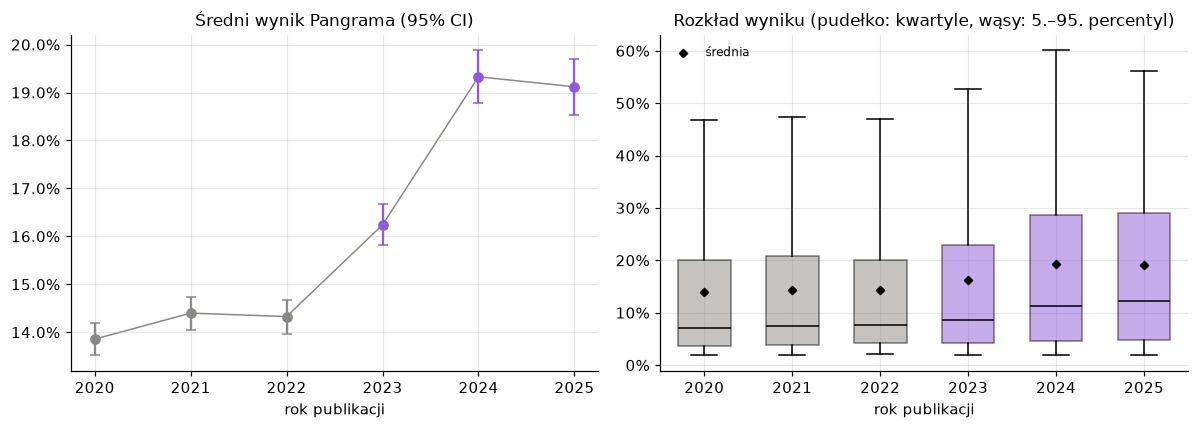

In [34]:
from matplotlib.ticker import PercentFormatter

pangram_all = data["pangram"]
LONG = 400  # od tylu słów wynik Pangrama wychodzi z „podłogi” (sekcja 12)


def mean_ci(values: pd.Series) -> tuple[float, float, float]:
    """Średnia i 95% przedział (przybliżenie normalne)."""
    mean = float(values.mean())
    half = (
        1.96 * float(values.std(ddof=1)) / np.sqrt(len(values))
        if len(values) > 1
        else np.nan
    )
    return mean, mean - half, mean + half


year_rows = []
for year, group in pangram_all.groupby("pub_year"):
    mean, low, high = mean_ci(group["pangram_score"])
    year_rows.append(
        {
            "rok": year,
            "n": len(group),
            "średni wynik": mean,
            "low": low,
            "high": high,
            "mediana": group["pangram_score"].median(),
            "udział tekstów z wynikiem ≥ 50%": (group["pangram_score"] >= 0.5).mean(),
        }
    )
by_year_scores = pd.DataFrame(year_rows).set_index("rok")
display(
    by_year_scores.assign(
        **{
            "95% CI średniej": [
                f"[{pct(lo)}; {pct(hi)}]"
                for lo, hi in zip(
                    by_year_scores["low"], by_year_scores["high"], strict=True
                )
            ]
        }
    )[
        [
            "n",
            "średni wynik",
            "95% CI średniej",
            "mediana",
            "udział tekstów z wynikiem ≥ 50%",
        ]
    ].style.format(
        {"średni wynik": pct, "mediana": pct, "udział tekstów z wynikiem ≥ 50%": pct}
    )
)

years = by_year_scores.index.to_numpy()
year_colors = [GRAY if y in GOLD_YEARS else DET_COLOR[PANGRAM] for y in years]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(years, by_year_scores["średni wynik"], color=GRAY, lw=1, zorder=1)
for y, mean, low, high, color in zip(
    years,
    by_year_scores["średni wynik"],
    by_year_scores["low"],
    by_year_scores["high"],
    year_colors,
    strict=True,
):
    axes[0].errorbar(
        y,
        mean,
        yerr=[[mean - low], [high - mean]],
        color=color,
        marker="o",
        ms=6,
        capsize=3,
        lw=1.5,
    )
axes[0].set_title("Średni wynik Pangrama (95% CI)")
box = axes[1].boxplot(
    [pangram_all.loc[pangram_all["pub_year"] == y, "pangram_score"] for y in years],
    positions=years,
    widths=0.6,
    whis=(5, 95),
    showfliers=False,
    patch_artist=True,
    medianprops={"color": "black"},
)
for patch, color in zip(box["boxes"], year_colors, strict=True):
    patch.set(facecolor=color, alpha=0.5)
axes[1].scatter(
    years,
    by_year_scores["średni wynik"],
    color="black",
    marker="D",
    s=14,
    zorder=3,
    label="średnia",
)
axes[1].set_title("Rozkład wyniku (pudełko: kwartyle, wąsy: 5.–95. percentyl)")
axes[1].legend(fontsize=8, loc="upper left")
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("rok publikacji")
fig.tight_layout()
plt.show()

- **Średni wynik jest płaski w latach 2020–2022** (13,8–15,8%, przedziały ufności się nakładają) **i rośnie po 2022 r.:** 18,2% w 2023, 20,8% w 2024 i 20,4% w 2025. Przedziały z lat 2023–2025 nie nakładają się z przedziałami z lat 2020–2022 (np. 2022: 13,4–15,3%, 2023: 17,1–19,4%). Średnio z całych okresów to wzrost z 14,7% do 19,6%, czyli około +5 pp.
- **Przesuwa się cały rozkład, nie tylko ogon:** mediana rośnie z 7–9% do 11–14%, 95. percentyl z 47% do 58% (dla całych okresów), a udział tekstów z wynikiem ≥ 50% z 3–4% do 7–11%.
- **Wzrost jest umiarkowany, a poziom bazowy niezerowy:** ludzkie teksty z lat 2020–2022 mają średnio prawie 15%. Średni wynik 20% nie znaczy więc, że 20% tekstów to AI.

,stratum,n_2020_22,średnia 2020–22,n_2023_25,średnia 2023–25,mediana słów 2020–22,mediana słów 2023–25,udział tekstów ≥400 słów 2023–25,zmiana (pp)
domain,,,,,,,,,
parezja.pl,S3,167,21.1%,10,47.7%,467,500,90.0%,+26.6
neon24.pl,S3,7,23.9%,215,47.1%,449,275,19.5%,+23.2
pikio.pl,S3,270,16.6%,16,40.0%,432,495,87.5%,+23.4
zmianynaziemi.pl,S2,551,11.1%,312,39.4%,285,350,31.4%,+28.3
globalna.info,S3,379,25.4%,336,31.1%,1007,984,95.8%,+5.7
demagog.org.pl,S2,576,24.6%,400,28.7%,847,850,91.2%,+4.1
oko.press,S3,600,25.3%,491,27.4%,1334,1704,98.0%,+2.0
gazeta.pl,S1,584,11.3%,24,26.4%,329,549,70.8%,+15.2
pap.pl,S2,83,18.8%,339,24.7%,515,564,80.2%,+5.9


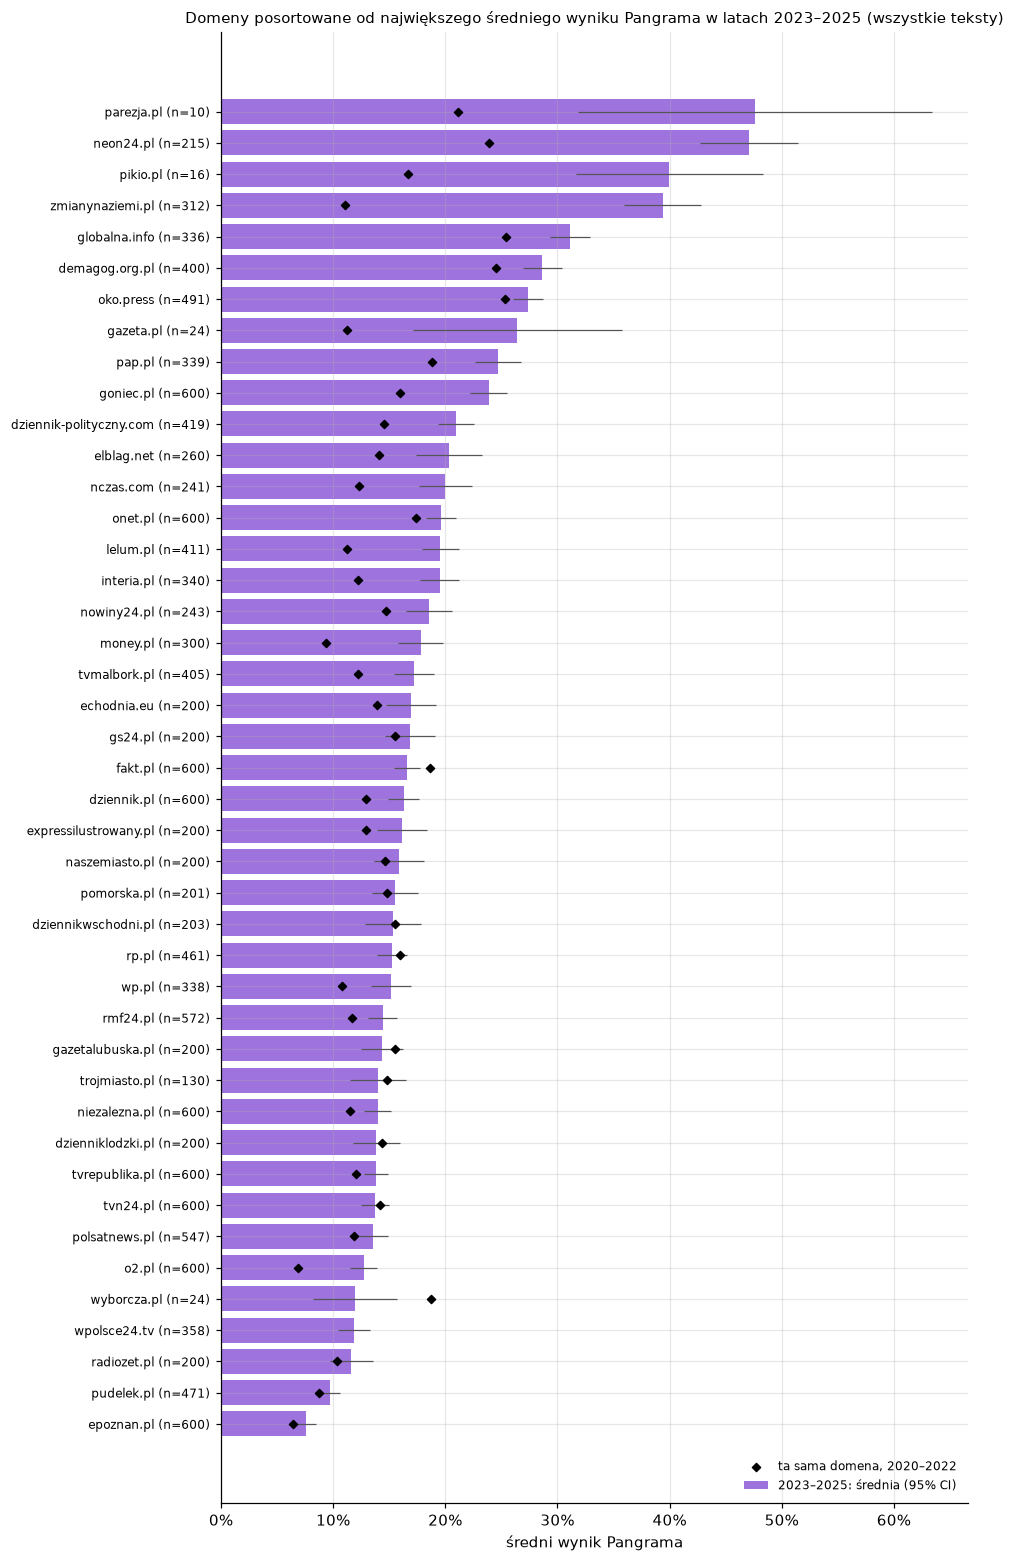

In [35]:
def domain_means(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for domain, group in df.groupby("domain"):
        before = group[group["human"]]
        after = group[~group["human"]]
        _, low, high = (
            mean_ci(after["pangram_score"])
            if len(after) > 1
            else (np.nan, np.nan, np.nan)
        )
        rows.append(
            {
                "domain": domain,
                "stratum": group["stratum"].iloc[0],
                "n_2020_22": len(before),
                "średnia 2020–22": before["pangram_score"].mean()
                if len(before)
                else np.nan,
                "n_2023_25": len(after),
                "średnia 2023–25": after["pangram_score"].mean()
                if len(after)
                else np.nan,
                "pół-szerokość CI 2023–25": (high - low) / 2,
                "mediana słów 2020–22": before["n_words"].median()
                if len(before)
                else np.nan,
                "mediana słów 2023–25": after["n_words"].median()
                if len(after)
                else np.nan,
                f"udział tekstów ≥{LONG} słów 2023–25": (
                    after["n_words"] >= LONG
                ).mean()
                if len(after)
                else np.nan,
            }
        )
    table = pd.DataFrame(rows).set_index("domain")
    table["zmiana (pp)"] = 100 * (table["średnia 2023–25"] - table["średnia 2020–22"])
    return table.sort_values("średnia 2023–25", ascending=False)


def plot_domain_means(table: pd.DataFrame, title: str, min_n: int) -> None:
    shown = table[table["n_2023_25"] >= min_n].iloc[::-1]  # największa średnia na górze
    fig, ax = plt.subplots(figsize=(9, 0.3 * len(shown) + 1.4))
    pos = np.arange(len(shown))
    ax.barh(
        pos,
        shown["średnia 2023–25"],
        xerr=shown["pół-szerokość CI 2023–25"],
        color=DET_COLOR[PANGRAM],
        alpha=0.85,
        error_kw={"lw": 0.8, "ecolor": "#555555"},
        label="2023–2025: średnia (95% CI)",
    )
    ax.scatter(
        shown["średnia 2020–22"],
        pos,
        color="black",
        marker="D",
        s=14,
        zorder=3,
        label="ta sama domena, 2020–2022",
    )
    ax.set_yticks(
        pos,
        [
            f"{d} (n={int(n)})"
            for d, n in zip(shown.index, shown["n_2023_25"], strict=True)
        ],
        fontsize=8,
    )
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("średni wynik Pangrama")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    plt.show()


domain_scores = domain_means(pangram_all)
display(
    domain_scores.drop(columns="pół-szerokość CI 2023–25").style.format(
        {
            "średnia 2020–22": pct,
            "średnia 2023–25": pct,
            "mediana słów 2020–22": "{:.0f}".format,
            "mediana słów 2023–25": "{:.0f}".format,
            f"udział tekstów ≥{LONG} słów 2023–25": pct,
            "zmiana (pp)": "{:+.1f}".format,
        },
        na_rep="–",
    )
)
plot_domain_means(
    domain_scores,
    "Domeny posortowane od największego średniego wyniku Pangrama w latach 2023–2025 (wszystkie teksty)",
    min_n=5,
)

Domeny są posortowane tak, jak prosiłeś: od największego średniego wyniku w latach 2023–2025. Czarny romb to średnia tej samej domeny w latach 2020–2022 (brak rombu = brak lub za mało tekstów z tego okresu).

- **Na szczycie:** `zmianynaziemi.pl` (48,2% wobec 8,6% w latach 2020–2022), `parezja.pl` (47,7%, ale tylko 6 tekstów), `pikio.pl` (39,3%, 13 tekstów), `neon24.pl` (34,3%, ale tylko 7 tekstów w latach 2020–2022). Pierwsza i trzecia to domeny, które wyszły też w analizie progowej (sekcja 13).
- **Sam ranking mierzy w dużej mierze długość artykułów** (zob. wykres niżej): domeny z długimi tekstami (`globalna.info`, `demagog.org.pl`, `oko.press`) mają wysoką średnią także w latach 2020–2022 (23–25%), więc ich miejsce w rankingu nie oznacza zmiany. Dlatego trzeba patrzeć na odstęp od rombu, a nie na samą długość słupka.
- **Zmiana względem 2020–2022:** średni wynik wzrósł w 30 z 40 domen, które mają teksty z obu okresów, a spadł w 10 (głównie duże portale: `tvn24.pl`, `polsatnews.pl`, `wp.pl`, `fakt.pl`, `rp.pl`). Największe wzrosty: `zmianynaziemi.pl` (+39,7 pp), `parezja.pl` (+22,5 pp, 6 tekstów), `gazeta.pl` (+20,3 pp, 7 tekstów), `pikio.pl` (+19,3 pp), `lelum.pl` (+14,4 pp), `nczas.com` (+13,0 pp).
- Przedziały ufności są szerokie (słupki błędów), zwłaszcza przy 6–25 tekstach, więc różnice między sąsiednimi domenami w rankingu nie są istotne. Ranking nie jest listą „winnych”.

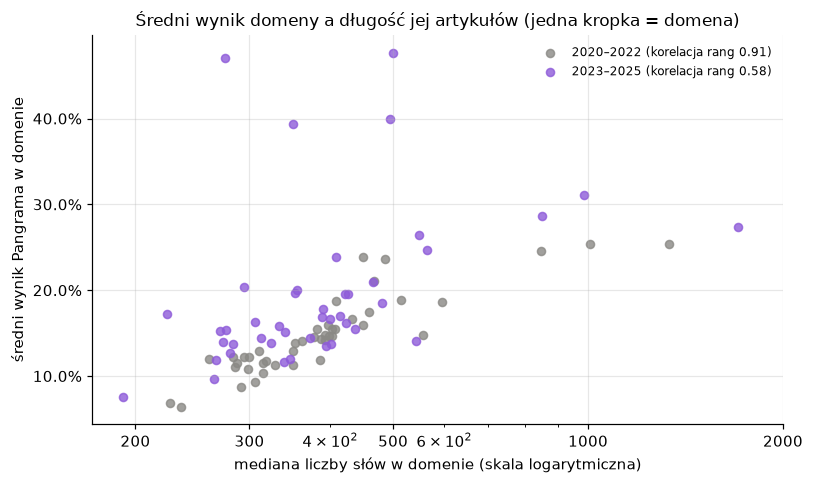

In [36]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for period, column, label, color in (
    ("średnia 2020–22", "mediana słów 2020–22", "2020–2022", GRAY),
    ("średnia 2023–25", "mediana słów 2023–25", "2023–2025", DET_COLOR[PANGRAM]),
):
    valid = domain_scores[[period, column]].dropna()
    rho = valid.rank().corr().iloc[0, 1]
    ax.scatter(
        valid[column],
        valid[period],
        color=color,
        s=28,
        alpha=0.8,
        label=f"{label} (korelacja rang {rho:.2f})",
    )
ax.set_xscale("log")
ax.set_xticks([200, 300, 500, 1000, 2000], ["200", "300", "500", "1000", "2000"])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("mediana liczby słów w domenie (skala logarytmiczna)")
ax.set_ylabel("średni wynik Pangrama w domenie")
ax.set_title("Średni wynik domeny a długość jej artykułów (jedna kropka = domena)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Korelacja rang między medianą długości artykułów domeny a jej średnim wynikiem wynosi **0,92 w latach 2020–2022** i 0,62 w latach 2023–2025.
W tekstach ludzkich średni wynik Pangrama jest więc w praktyce miarą długości artykułów domeny. To jest powód, dla którego ranking domen po samym średnim wyniku trzeba czytać ostrożnie.

W latach 2023–2025 korelacja jest słabsza, bo kilka domen leży wyraźnie **ponad** linią trendu: `zmianynaziemi.pl`, `pikio.pl` i `neon24.pl` (34–48% przy medianie 300–500 słów), a także `tvmalbork.pl` (22% przy medianie 274 słów). Ich teksty mają wyższy wynik, niż wynika z długości.

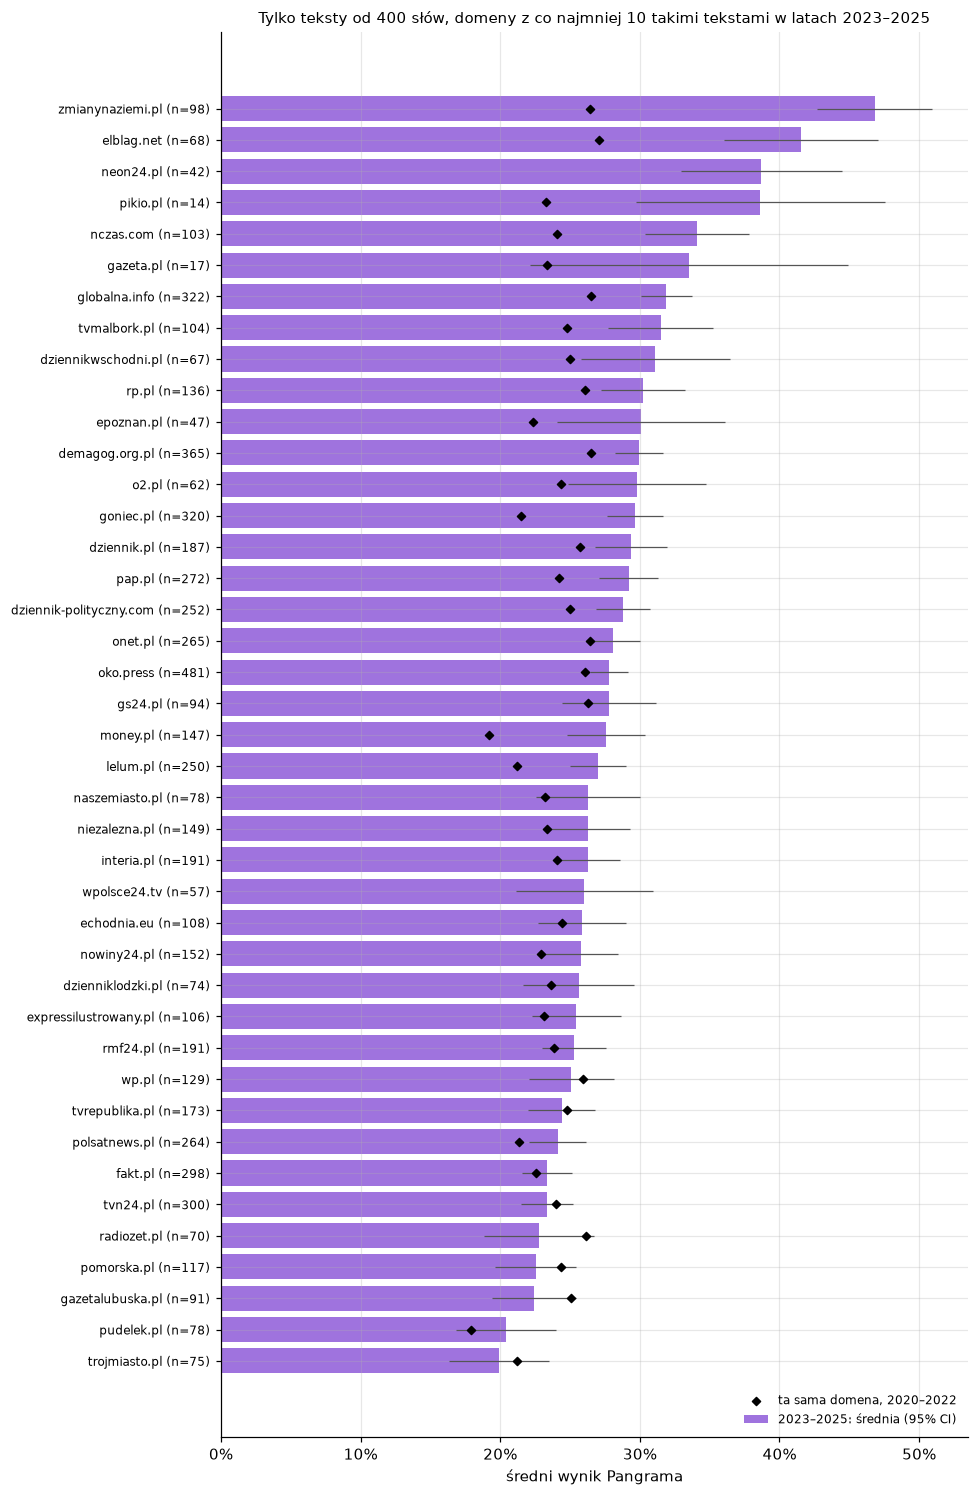

Zmiana średniego wyniku (2023–25 minus 2020–22, tylko teksty od 400 słów) w domenach z co najmniej 10 takimi tekstami w obu okresach:
39 domen; dodatnia zmiana w 32, mediana zmiany +3.0 pp


,n_2020_22,średnia 2020–22,n_2023_25,średnia 2023–25,zmiana (pp)
domain,,,,,
zmianynaziemi.pl,123,26.4%,98,46.8%,+20.4
pikio.pl,168,23.2%,14,38.6%,+15.4
elblag.net,183,27.1%,68,41.5%,+14.4
gazeta.pl,214,23.4%,17,33.5%,+10.2
nczas.com,176,24.1%,103,34.1%,+10.0
money.pl,38,19.2%,147,27.6%,+8.4
goniec.pl,184,21.5%,320,29.7%,+8.2
epoznan.pl,68,22.4%,47,30.1%,+7.7
tvmalbork.pl,188,24.7%,104,31.5%,+6.8


In [37]:
long_scores = domain_means(pangram_all[pangram_all["n_words"] >= LONG])
# Podstawa z lat 2020–22 tylko tam, gdzie jest co najmniej 10 długich tekstów
long_scores.loc[long_scores["n_2020_22"] < 10, "średnia 2020–22"] = np.nan
plot_domain_means(
    long_scores,
    f"Tylko teksty od {LONG} słów, domeny z co najmniej 10 takimi tekstami w latach 2023–2025",
    min_n=10,
)
print(
    "Zmiana średniego wyniku (2023–25 minus 2020–22, tylko teksty od "
    f"{LONG} słów) w domenach z co najmniej 10 takimi tekstami w obu okresach:"
)
comparable = long_scores[
    (long_scores["n_2023_25"] >= 10) & (long_scores["n_2020_22"] >= 10)
]
print(
    f"{len(comparable)} domen; dodatnia zmiana w {int((comparable['zmiana (pp)'] > 0).sum())}, "
    f"mediana zmiany {comparable['zmiana (pp)'].median():+.1f} pp"
)
display(
    comparable.sort_values("zmiana (pp)", ascending=False)
    .head(10)[
        ["n_2020_22", "średnia 2020–22", "n_2023_25", "średnia 2023–25", "zmiana (pp)"]
    ]
    .style.format(
        {
            "średnia 2020–22": pct,
            "średnia 2023–25": pct,
            "zmiana (pp)": "{:+.1f}".format,
        }
    )
)

Przy tej samej długości (teksty od 400 słów) baza ludzka jest wyższa (24,8% wobec 14,7% dla wszystkich tekstów), a po 2022 r. rośnie do 28,7%.

- W 35 domenach z co najmniej 10 takimi tekstami w obu okresach średni wynik wzrósł w 30, a mediana zmiany to +2,9 pp.
- **Na czele zmian są te same domeny co w sekcji 13**: `zmianynaziemi.pl` (+26,4 pp), `tvmalbork.pl` (+12,6 pp), `pikio.pl` (+12,3 pp), `nczas.com` (+12,2 pp) i `lelum.pl` (+10,6 pp), a do nich dołączają `money.pl` (+11,7 pp) i `goniec.pl` (+10,7 pp). Wzrost w tych domenach nie jest więc efektem długości artykułów.
- Próbki są małe (10–50 tekstów), więc przedziały ufności są szerokie, a kolejność w środku rankingu nie jest istotna.

## 16. Wnioski i następne kroki


*Stan na wyniki z `data/detect/` (5026 artykułów, 44 domeny; trzy detektory: Binoculars i Fast-DetectGPT na dwóch parach Bielika oraz Pangram EditLens). Po zmianie danych lub ustawień należy ponownie uruchomić notebook i zaktualizować liczby w tej sekcji.*

### Co ustaliliśmy

**Czy narzędzia działają**

1. **Implementacja działa i jest zgodna z literaturą.** Binoculars na próbce Śmigiela daje trafność 0,77–0,79 (AUC 0,83–0,85), a w PolEval 2025 zwycięskie zgłoszenie z tą metodą miało około 0,80. Binoculars jest najlepszym z detektorów Bielika, a zwykła perplexity najgorszym. Pangram EditLens, mimo uczenia wyłącznie na angielskim, ma na Śmigielu AUC 0,80 i wykrywa 40% tekstów AI przy FPR 5% (21% przy 1%), czyli nieco gorzej niż Fast-DetectGPT (46–47% i 20–27%) i wyraźnie gorzej niż Binoculars (52% i 35%).
2. **Większy model Bielika nie pomaga wyraźnie.** Para 4.5B (8-bit) ma AUC 0,85 wobec 0,83 dla 1.5B, a przy FPR 1% czułość nawet niższą (0,27 wobec 0,35). Dwa modele traktujemy jako wzajemną kontrolę, nie jako „słabszy i mocniejszy”.
3. **Progi przenoszą się na nowe dane.** Na odłożonym zbiorze `test` (lata 2020–2022) odsetek fałszywych alarmów wynosi 3,8–6,9% przy docelowych 5% (Pangram: 4,2%), a w kolejnych latach 2020–2022 odsetek oznaczonych jest płaski (test placebo przechodzi, także dla Pangrama).

**Czy po 2022 r. przybyło tekstów podobnych do AI**

4. **Bielik: mała nadwyżka albo jej brak, zależnie od poprawki na długość.** Przy jednym progu dla wszystkich: Binoculars 5,0% → 5,8% (1.5B, p≈0,10) i 4,8% → 5,7% (4.5B, p≈0,10), AUC „po kontra przed” równe 0,50; pozostałe detektory różnią się o 1 punkt procentowy lub mniej. Gdy próg ustawimy osobno w przedziałach długości (sekcja 12), pojawia się nadwyżka +1,2 pp (1.5B, p=0,03) i +2,0 pp (4.5B, p=0,001) przy FPR 5%. Ta analiza została wybrana po zobaczeniu wyników, więc traktujemy ją jako dodatkową.
5. **Pangram: wyraźna nadwyżka.** Odsetek oznaczonych rośnie z 4,9% do 9,9% (FPR 5%) i z 1,0% do 3,9% (FPR 1%), AUC „po kontra przed” to 0,58 (95% CI 0,56–0,59), a nadwyżka jest dodatnia przy każdym progu od 0,5% do 15% FPR. Odsetek jest płaski do końca 2022 r. i rośnie od 2023 r. (kwartalnie 9–16% w latach 2024–2025, z wyjątkiem jednego kwartału). Bez żadnego progu (sekcja 15) średni wynik rośnie z 14,7% w latach 2020–2022 do 19,6% w latach 2023–2025, a w 30 z 40 domen jest wyższy niż wcześniej. Ranking domen po samym średnim wyniku silnie zależy od długości artykułów (korelacja rang 0,92 w latach 2020–2022), dlatego czytamy go względem tej samej domeny i w widoku od 400 słów.
6. **Wzrost u Pangrama nie jest artefaktem długości ani jednej domeny.** Przesunięcie jest widoczne w każdym z ośmiu przedziałów długości (AUC 0,53–0,62) i po kalibracji progu w przedziałach długości. Pięć domen (`zmianynaziemi.pl`, `nczas.com`, `pikio.pl`, `tvmalbork.pl`, `lelum.pl`, wszystkie z S2 lub S3) ma q<0,10 i odpowiada za około połowę nadwyżki, ale po ich odjęciu zostaje +2,6 pp (p<0,001), a 28 z 40 domen ma dodatnią nadwyżkę (p=0,003). Mała nadwyżka Bielika pochodzi natomiast z tych samych pięciu domen i po ich odjęciu znika.
7. **Dwa niezależne detektory zgadzają się selektywnie po 2022 r.** Wspólnie oznaczają 28 tekstów z lat 2023–2025 wobec oczekiwanych 12,6 (p=2·10⁻⁵), a w latach 2020–2022 tylko 2 wobec oczekiwanych 6,9. Pangram i Binoculars nie korelują ze sobą na poziomie tekstu (−0,03), więc nie jest to ten sam sygnał podany dwa razy. Te 28 tekstów to najmocniejsza lista kandydatów (`data/detect/candidates_consensus.csv`).
8. **Skala zjawiska jest niepewna: od około 1–2% do około 14% artykułów z lat 2023–2025.** Dolny kraniec to ostrożna reguła „oba detektory oznaczają” (1,4% przy FPR 1%), reguła „któryś” daje 5–8%, a górny to Pangram sam (około 14%), który jest najmniej wiarygodny. Szacunki zakładają czułość ze Śmigiela, której na naszych danych **nie znamy**.
9. **Moc testu na poziomie domen jest niska.** Przy 75 tekstach na okres pojedyncza domena jest wykrywana z mocą 80% dopiero wtedy, gdy AI stanowi około 30% jej tekstów z lat 2023–2025 (dla Binoculars). Detektory Bielika nie dają silnego sygnału na poziomie domen (po poprawce na 44 testy istotna jest jedna domena w jednym modelu, `demagog.org.pl`, q=0,05), a lista 66 tekstów oznaczonych przez oba modele Bielika to głównie szum (oczekiwane fałszywe alarmy: około 53). `tvmalbork.pl` ma przy tym wysoki poziom fałszywych alarmów Binoculars już w 2020–2022 (8–9%).

### Ograniczenia, które trzeba opisać w raporcie

- **Czułość znamy tylko ze Śmigiela**, czyli dla krótkich fragmentów (mediana 49 słów) i generatorów open-source (Bielik, PLLuM, Llama, Mistral, Gemma). Serwisy publikujące masowo treści AI najpewniej używają ChatGPT, Gemini lub Claude. Możliwe, że wykrywamy je gorzej, niż pokazuje Śmigiel.
- **Pangram EditLens był uczony tylko na angielskim**, a jego wynik ma nieciągłość przy około 400 słowach (prawdopodobnie związaną z limitem 1024 tokenów; nie sprawdziliśmy tego). Wzrost odsetka oznaczonych po 2022 r. może częściowo odzwierciedlać zmianę stylu, formatu lub składu domen, a nie AI.
- **Wzrost zaczyna się około premiery ChatGPT**, co jest zgodne z hipotezą, ale jej nie dowodzi. Dowodem byłaby dopiero ręczna ocena tekstów oznaczonych i niezależny pomiar czułości.
- **Fałszywe alarmy mają swoje typy:** komunikaty instytucji i agencji powielane na wielu serwisach (liczą się podwójnie), krótkie notki lokalne, zestawienia.
- **Wiele wariantów analizy.** Poza analizą główną (sekcje 4–5) wykonaliśmy dodatkowe (przedziały długości, odjęcie domen, reguły łączone) po zobaczeniu wyników. Brzegowe p-wartości (około 0,03) traktujemy ostrożnie, a wnioski opieramy na wynikach powtarzających się w kilku analizach.
- **Teksty AI mogą być zmieszane z ludzkimi** (AI pisze szkic, człowiek poprawia) i wtedy detektory widzą je słabo.
- **Bielik ocenia tylko pierwsze 512 tokenów** (64% tekstów jest dłuższych), a jego odsetek fałszywych alarmów zależy od długości tekstu (sekcja 12).
- **„Ludzkie” teksty z lat 2020–2022 to założenie.** Mogą w nich być teksty generowane wcześniejszymi technikami (szablony, automatyczne tłumaczenia).
- **Bielik mógł widzieć nasze artykuły podczas trenowania**, co obniża perplexity tekstów ludzkich. Test placebo i porównanie z latami 2020–2022 częściowo to kontrolują.
- **Próbka jest mała** (25–75 tekstów na domenę i okres), a progu nie da się ustawić osobno dla każdej domeny.

### Następne kroki (od najważniejszego)

1. **Ślepy przegląd ręczny.** 28 tekstów konsensusu, kilkanaście najwyżej ocenionych tekstów Pangrama z pięciu domen (sekcja 13) i 30–50 losowych tekstów z lat 2020–2022, wymieszane; osoba oceniająca nie wie, które są które. Zapisać oceny w pliku. To rozstrzyga, czy oznaczenia faktycznie wskazują AI, i daje pierwszy pomiar trafności na naszych danych.
2. **Zmierzyć czułość na własnych danych.** Dla kilkuset tytułów lub leadów z lat 2020–2022 wygenerować artykuły kilkoma modelami (Bielik i przynajmniej jeden komercyjny, np. ChatGPT lub Gemini), przepuścić przez te same detektory i obliczyć TPR przy FPR 5% i 1%. Bez tego nie wiemy, czy „brak sygnału” znaczy „brak AI”, czy „detektor jej nie widzi”.
3. **Wyjaśnić nieciągłość Pangrama przy około 400 słowach** (np. policzyć wynik tych samych tekstów ucinanych do 512 i 1024 tokenów; sprawdzić, czy to cecha modelu, czy implementacji) oraz **powtórzyć Bielika z większym limitem** (`--max-tokens 1024` do nowego pliku), bo nadwyżka Bielika zależy od korekty na długość.
4. **Niezależna weryfikacja Pangramem komercyjnym** (zespół pisał do nich o dostęp badawczy) co najmniej dla kandydatów i próbki kontrolnej z lat 2020–2022. Obecny Pangram jest otwartym modelem uczonym na angielskim.
5. **Dobrać więcej tekstów dla domen-kandydatów** (np. `pikio.pl` ma tylko 13 tekstów z lat 2023–2025), zwiększając kwotę w ustawieniach pobierania (`articles_per_domain_year`).
6. **Opisać wynik jako przedział, nie jako liczbę „farm”.** Uczciwe sformułowanie: „detektory wskazują na nadwyżkę tekstów podobnych do AI po 2022 r. skupioną w kilku serwisach z S2 i S3; przy założonej czułości udział wynosi od około 1–2% do około 14%; wynik wymaga potwierdzenia ręcznym przeglądem”.
7. **Jeśli punkt 2 pokaże niską czułość**, rozważyć detektor trenowany nadzorowanie (np. Qwen3, XLM-R lub mDeBERTa) na Śmigielu i własnych syntetycznych newsach. W literaturze (CEAID, PolEval) takie modele są wyraźnie dokładniejsze w znanej domenie, ale gorzej uogólniają na nowe generatory, więc wymagałyby tej samej kontroli.
